# Paisabazaar Credit Score Classification Project

#### Name: Siddhant Iyer

<b>Project Type - EDA/Classification</b>

### Project Overview

**Business Context**

- Paisabazaar is a financial services company that assists customers in finding and applying various banking and credit products.
- Important part of their job is to assess the <u>creditworthiness</u> of individuals, which is important for loan approval and risk management.
- Credit score is an important metric used to determine whether the person will be able to repay their loans or credit balances.
- Accurate classification of credit score can help Paisabazaar enhance their credit assessment processes, reduce risk of loan defaults, offer personalized financial advice to their customers.

- Develop a model that predicts the credit score of individuals based on various features, such as income, credit card usage and payment behavior.

**What is Credit Score?**

- A credit score is the numerical representation of a customer's creditworthiness. In other words, if a bank lends a person money on loan, the credit score will determine how capable and likely they are to return that money with interest and on time.
- It is used to assess financial reliability
- The score ranges from 300 to 850 and in this dataset, it is 'Poor', 'Standard', 'Good'

High scores means that the customer is trustworthy to lenders and likely to get:
1. Lower interest rates
2. Higher credit limits
3. Easier loan approvals

There are 5 main factors affecting credit score:
1. <b>Payment History (35%)</b> - Whether the customer has paid past debts on time. Late or missed payments severely hurt this.
2. <b>Amounts Owed (Credit Utilization) (30%)</b> - How much of the available credit is the customer using? Ideally, utilization should be below 30%

Credit Utilization = (Total credit used/Total credit limit) x 100

4. <b>Length of credit history (15%)</b> - How long the customer has had credit accounts. Older accounts improve the score. It includes things like: average age of all accounts, age of oldest accounts, age of newest accounts.
5. <b>Credit Mix (10%)</b> - Having a variety (credit card, loan, mortgage) shows the customer can handle multiple types of credits responsibly
6. <b>New Credit (Recent Inquiries) (10%)</b> - Opening many new accounts or having too many hard inquiries in a short time can hurt the score.

### Problem Statement 

- Build a predictive classification model that can use the different information and features of a Paisa Bazaar customer and be able to classify whether he/she has a 'Poor', 'Standard' or 'Good' credit score.

### Feature Information

1. **Customer_ID** - Unique identifier for each customer
2. **Month** - Recording month of the data snapshot 
3. **Name** - Customer's name
4. **Age** - Customer's age and it impacts credit history length potential (1-100)
5. **SSN** - Social Security Number of the customer
6. **Occupation** - Customer's occupation (typically indicates income stability)
7. **Annual_Income** - Total yearly earnings of the customer (repayment capacity indicator)
8. **Monthly_Inhand_Salary** - Take home pay after deductions (actual disposable income)
9. **Num_Bank_Accounts** - Number of bank accounts held by the customer
10. **Num_Credit_Card** - Number of active credit cards
11. **Interest_Rate** - Average rate of interests on loans/cards
12. **Num_of_Loan** - Total number of loans taken by the customer 
13. **Type_of_Loan** - Types of loans taken by the customer ("Auto Loan", "Personal Loan", "Credit Builder Loan")
14. **Delay_from_due_date** - Average days of payment delay
15. **Num_of_Delayed_Payment** - Total count of delayed payments
16. **Changed_Credit_Limit** - Frequency of credit limit changes
17. **Num_Credit_Inquiries** - Number of hard credit checks (too many can hurt the score)
18. **Credit_Mix** - Quality of credit portfolio diversity ("Good", "Bad", "Standard")
19. **Outstanding_Debt** - Total unpaid debt across all accounts
20. **Credit_Utilization_Ratio** - Percentage of credit limit used (key factor in credit scoring)
21. **Credit_History_Age** - Duration of credit relationship (in days)
22. **Payment_of_Min_Amount** - Whether customer pays only minimum amount (Yes/No)
23. **Total_EMI_per_month** - Monthly loan installment obligations
24. **Amount_invested_monthly** - Monthly investment amount (financial planning indicator)
25. **Payment_Behaviour** - Spending v/s payment pattern (eg: High_spent_Medium_value payments)
26. **Monthly_Balance** - Available balance after expenses
27. **Credit_Score** - A score that represent's an individual's creditworthiness - how likely they are to repay the borrowed money on time ("Poor", "Good", "Standard")

### Importing the Libraries

In [2]:
# Importing the basic libraries

import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from warnings import filterwarnings
filterwarnings("ignore")

### Loading the data

In [405]:
df = pd.read_csv(r"C:\Users\Siddhant Iyer\OneDrive\Desktop\Data Analytics\LabMentix Files\Project 1 (Paisa Bazaar)\dataset_2.csv")

In [406]:
df = df.set_index('ID') # set ID as the index because it represents a serial number for each record within the table
df.index.name = None # No need for it to be a separate column as it is redundant and offers no valuable information.

In [407]:
# Looking at the first 10 rows of the data
df.head(5) 

,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [408]:
# Looking at the last 5 rows of the data
df.tail(5)

,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,6.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,6.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,6.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,6.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard
155629,37932,8,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,6.0,...,Good,502.38,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor


### Basic Information About the Data

<b>Data Dimensionality</b>

In [409]:
df.shape # there are 100000 rows and 27 columns within this table

(100000, 27)

<b>Dataset Info</b>

In [410]:
df.columns # Without the ID column, the rest of the columns including the target variable 'Credit_Score' is present

Index(['Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [411]:
df.info()

# Can see all the features within the table and their respective datatypes.

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 5634 to 155629
Data columns (total 27 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Customer_ID               100000 non-null  int64  
 1   Month                     100000 non-null  int64  
 2   Name                      100000 non-null  object 
 3   Age                       100000 non-null  float64
 4   SSN                       100000 non-null  float64
 5   Occupation                100000 non-null  object 
 6   Annual_Income             100000 non-null  float64
 7   Monthly_Inhand_Salary     100000 non-null  float64
 8   Num_Bank_Accounts         100000 non-null  float64
 9   Num_Credit_Card           100000 non-null  float64
 10  Interest_Rate             100000 non-null  float64
 11  Num_of_Loan               100000 non-null  float64
 12  Type_of_Loan              100000 non-null  object 
 13  Delay_from_due_date       100000 non-null  flo

- Columns like <u>age</u>, <u>SSN</u>, <u>Name</u>, <u>Occupation</u> won't contribute towards the model's predictive performance so they can be eliminated to simplify the data.

<b>Checking the datatypes</b>

In [412]:
df.dtypes

Customer_ID                   int64
Month                         int64
Name                         object
Age                         float64
SSN                         float64
Occupation                   object
Annual_Income               float64
Monthly_Inhand_Salary       float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Type_of_Loan                 object
Delay_from_due_date         float64
Num_of_Delayed_Payment      float64
Changed_Credit_Limit        float64
Num_Credit_Inquiries        float64
Credit_Mix                   object
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount        object
Total_EMI_per_month         float64
Amount_invested_monthly     float64
Payment_Behaviour            object
Monthly_Balance             float64
Credit_Score                 object
dtype: object

In [413]:
df.dtypes.value_counts()

float64    18
object      7
int64       2
Name: count, dtype: int64

- There are 18 columns with float data type, 2 with integer and 7 as text or categorical. Which means out of 27, there are 20 numeric and 7 categorical variables.

<b>Describing the Data<b>

In [414]:
df.describe() 

,Customer_ID,Month,Age,SSN,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,25982.666640,4.500000,33.316340,5.004617e+08,50505.123449,4197.270835,5.368820,5.533570,14.53208,3.532880,21.08141,13.313120,10.470323,5.798250,1426.220376,32.285173,221.220460,107.699208,55.101315,392.697586
std,14340.543051,2.291299,10.764812,2.908267e+08,38299.422093,3186.432497,2.593314,2.067098,8.74133,2.446356,14.80456,6.237166,6.609481,3.867826,1155.129026,5.116875,99.680716,132.267056,39.006932,201.652719
min,1006.000000,1.000000,14.000000,8.134900e+04,7005.930000,303.645417,0.000000,0.000000,1.00000,0.000000,0.00000,0.000000,0.500000,0.000000,0.230000,20.000000,1.000000,0.000000,0.000000,0.007760
25%,13664.500000,2.750000,24.000000,2.451686e+08,19342.972500,1626.594167,3.000000,4.000000,7.00000,2.000000,10.00000,9.000000,5.380000,3.000000,566.072500,28.052567,144.000000,29.268886,27.959111,267.615983
50%,25777.000000,4.500000,33.000000,5.006886e+08,36999.705000,3095.905000,5.000000,5.000000,13.00000,3.000000,18.00000,14.000000,9.400000,5.000000,1166.155000,32.305784,219.000000,66.462304,45.156550,333.865366
75%,38385.000000,6.250000,42.000000,7.560027e+08,71683.470000,5957.715000,7.000000,7.000000,20.00000,5.000000,28.00000,18.000000,14.850000,8.000000,1945.962500,36.496663,302.000000,147.392573,71.295797,463.215683
max,50999.000000,8.000000,56.000000,9.999934e+08,179987.280000,15204.633333,11.000000,11.000000,34.00000,9.000000,62.00000,25.000000,29.980000,17.000000,4998.070000,50.000000,404.000000,1779.103254,434.191089,1183.930696


- From the data description, there seems to be a couple of columns with outlier values such as <u>Annual_Income</u>, <u>Monthly_Inhand_Salary</u>, <u> Delay_from_due_date</u>, <u>Outstanding_Debt</u>, <u>Total_EMI_per_month</u>.
- But to verify that these values are true outliers and not legitimate data points with some extreme values that are valuable to the predictive outcome, a boxplot would have to be generated to visualize this.

<b>Identifying Missing/Null Values</b>

In [415]:
df.isnull().sum()

# There are no missing/NULL values within the table

Customer_ID                 0
Month                       0
Name                        0
Age                         0
SSN                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
Credit_Score                0
dtype: int64

<b>Identifying unique values</b>

In [416]:
df.nunique()

# There are a lot of non-unique values within each column of the table

Customer_ID                  12500
Month                            8
Name                         10128
Age                             43
SSN                          12500
Occupation                      15
Annual_Income                12488
Monthly_Inhand_Salary        13241
Num_Bank_Accounts               12
Num_Credit_Card                 12
Interest_Rate                   34
Num_of_Loan                     10
Type_of_Loan                  6261
Delay_from_due_date             63
Num_of_Delayed_Payment          26
Changed_Credit_Limit          3452
Num_Credit_Inquiries            18
Credit_Mix                       3
Outstanding_Debt             12203
Credit_Utilization_Ratio    100000
Credit_History_Age             404
Payment_of_Min_Amount            3
Total_EMI_per_month          11890
Amount_invested_monthly      12261
Payment_Behaviour                6
Monthly_Balance              98494
Credit_Score                     3
dtype: int64

<b>Identifying duplicate values </b>

In [417]:
df.duplicated().sum() 

# There are no duplicate records in the table

0

- Although each column has a lot of non-unique values, there are no duplicate records where each column is the same.
- This means that we don't need to handle the duplicate records as they still provide valuable information to the predictive outcome.

<b>Visualizing Outliers In Each Column</b>

In [418]:
numeric_columns = df.select_dtypes(include = 'number').columns # selecting only numerical columns
numeric_df = df[numeric_columns]

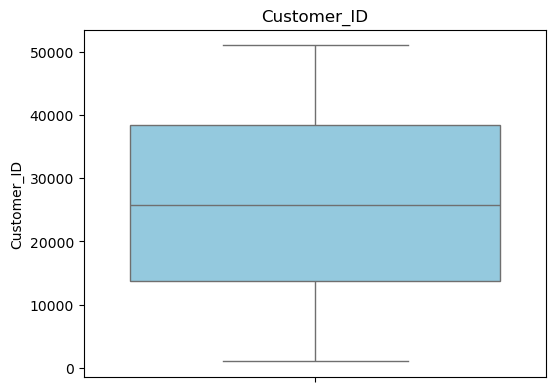

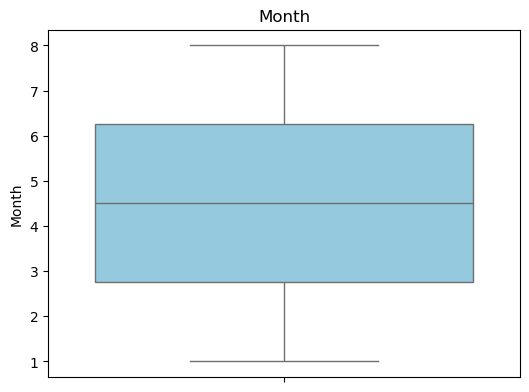

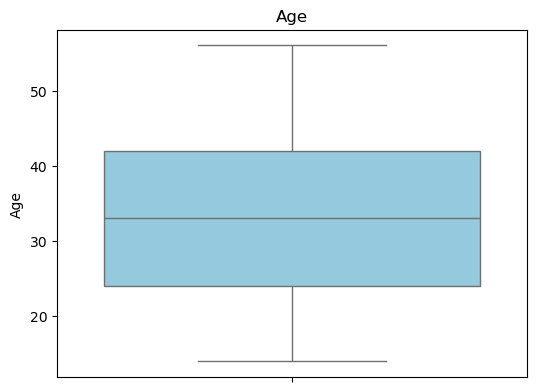

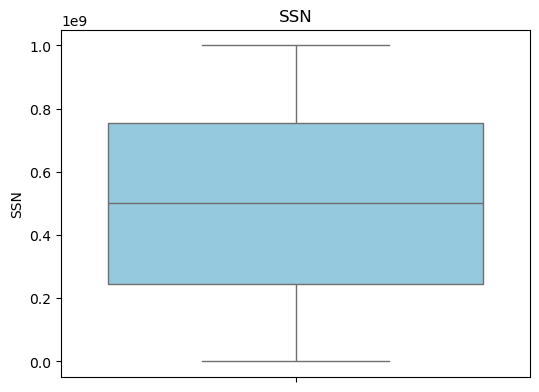

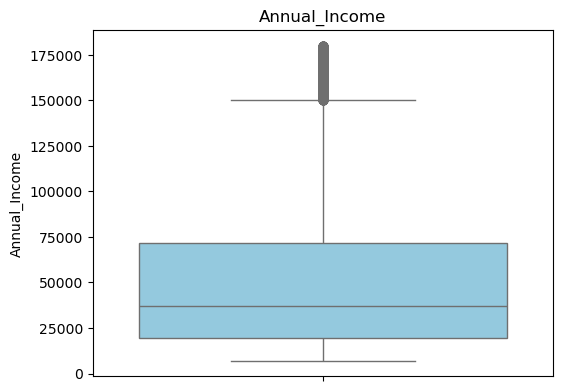

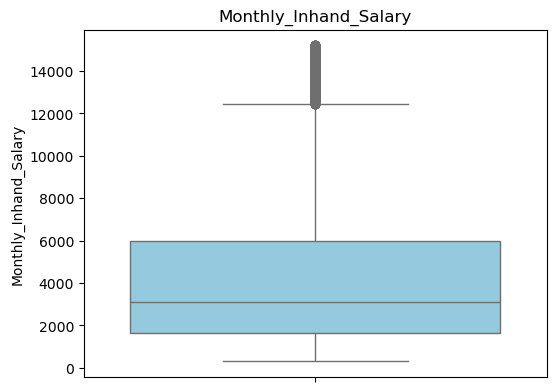

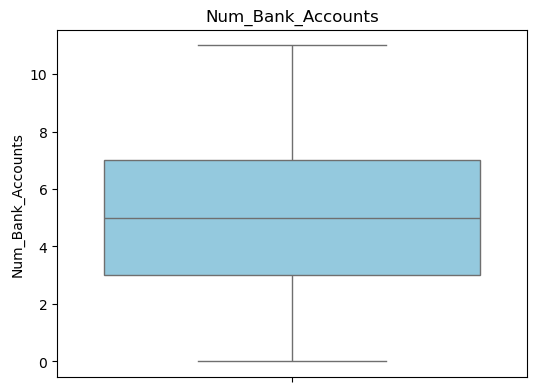

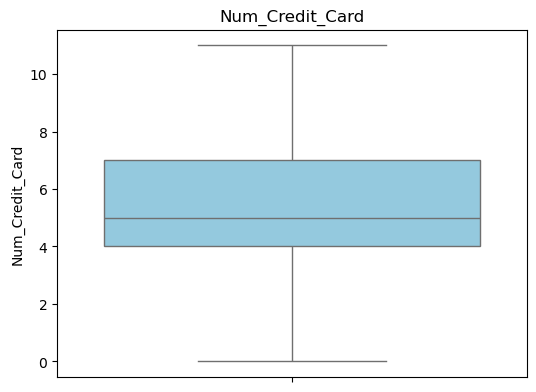

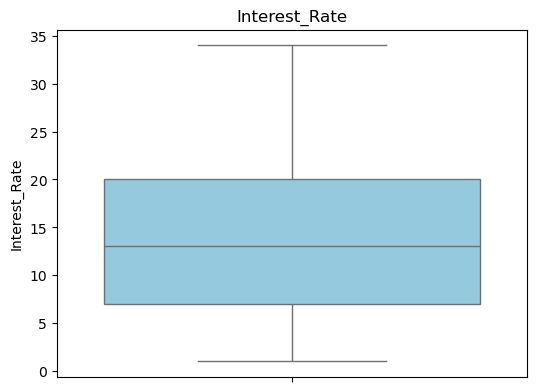

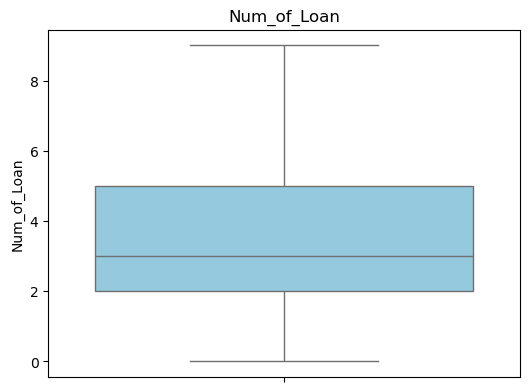

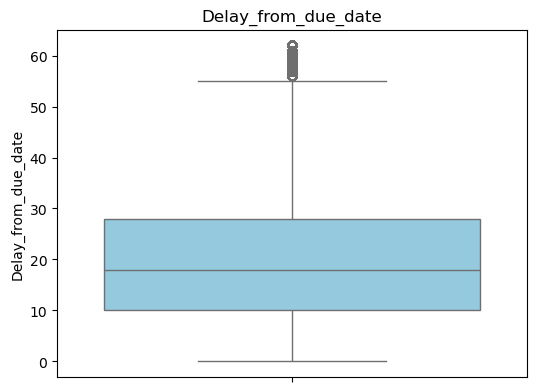

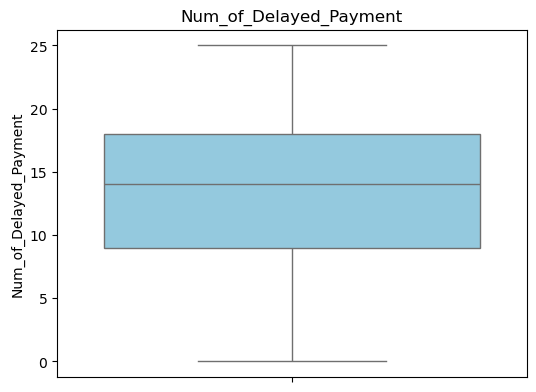

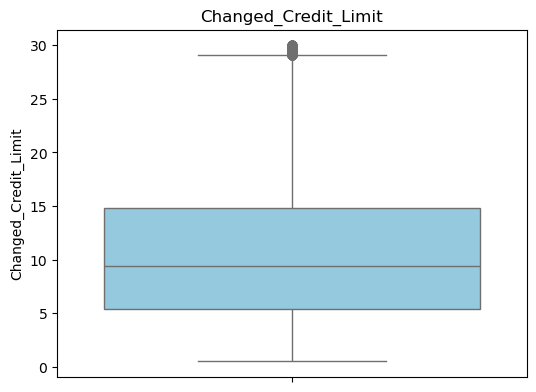

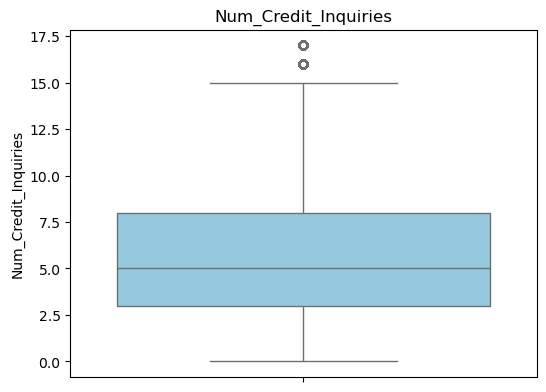

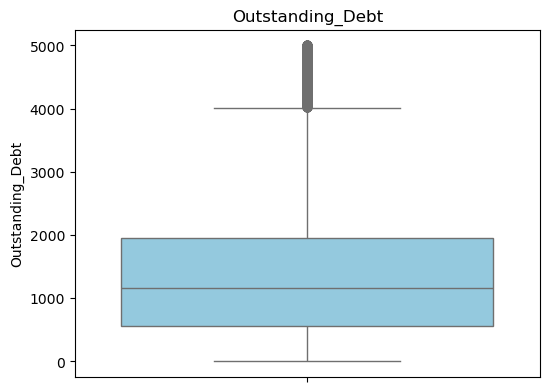

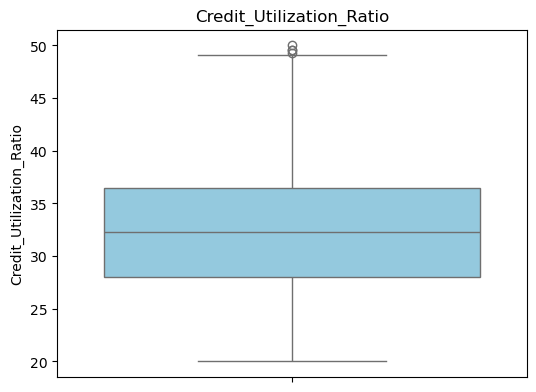

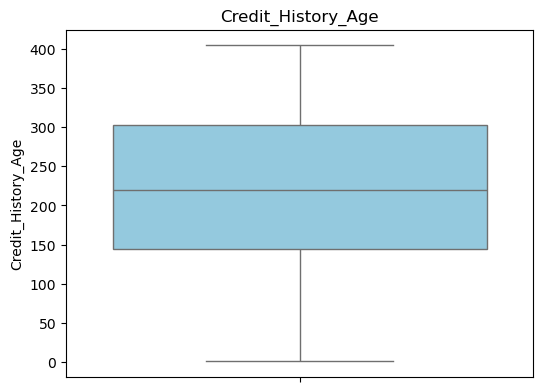

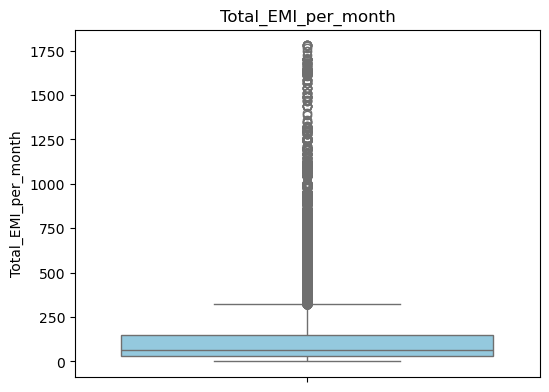

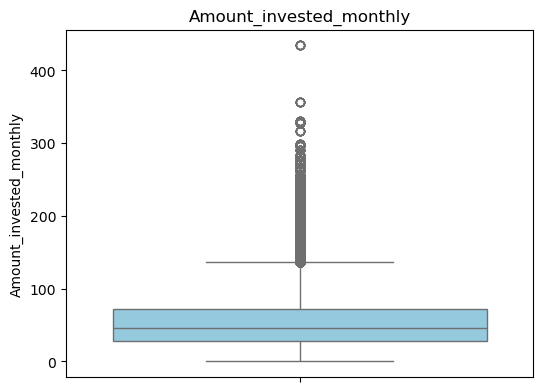

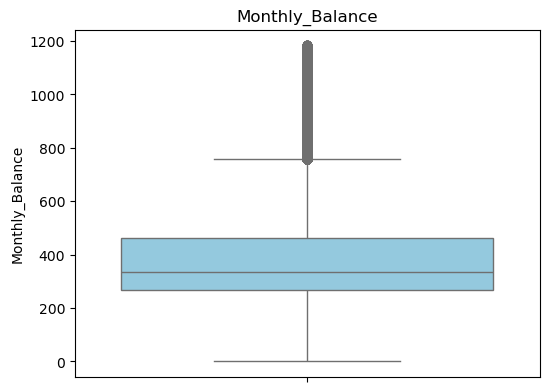

In [419]:
# Creating boxplots for every numerical column

for i, col in enumerate(numeric_df.columns, 1): 
    plt.figure(figsize=(20, 15))
    plt.subplot(4, 4, 1)
    sns.boxplot(y=numeric_df[col], color='skyblue')
    plt.title(f"{col}")
    plt.tight_layout()
    plt.show() 

In [420]:
# Counting the number of outliers in each column by defining a function that would take the column name as an input

def outliers(column):
    new_df = df[column].sort_values(ascending = True) # sorts the values in ascending order
    q1 = new_df.quantile(0.25) # calculates the lower quartile
    q3 = new_df.quantile(0.75) # calculates the upper quartile
    IQR = q3 - q1 # calculates the inter-quartile range
    lower_bound = q1 - 1.5*IQR
    upper_bound = q3 + 1.5*IQR
    outlier = (new_df < lower_bound)|(new_df > upper_bound) 
    # finds the outliers by filtering out values that are either less than the lower bound or greater than the upper bound
    return outlier.sum()

In [421]:
outliers("Monthly_Balance") # testing the function

7400

In [422]:
# Storing the columns and number of outliers in a DataFrame
outlier_df = pd.DataFrame()
outlier_df["Columns"] = numeric_df.columns # all the numerical columns 
outlier_df["Number of Outlier"] = [outliers(col) for col in numeric_df.columns] 
# number of outliers using the outlier function created

In [423]:
outlier_df

,Columns,Number of Outlier
0,Customer_ID,0
1,Month,0
2,Age,0
3,SSN,0
4,Annual_Income,2000
5,Monthly_Inhand_Salary,2017
6,Num_Bank_Accounts,0
7,Num_Credit_Card,0
8,Interest_Rate,0
9,Num_of_Loan,0


- From the table above, we can see that columns like Month, Credit_History_Age, which are more likely to have erroneous values or impossible values, don't have outliers.
- Other columns have more than 500 values that are deemed as outliers but by looking at the boxplots for each one of them, we can see that a lot of those points are not extreme values but legitimate data values. 
- However, one thing to note here is that, if we look at the description of the data, within the age column, there is are several records with Ages < 18. Credit scores are not applicable to those who are not adults yet and are below 18. That needs to be checked once.

<b>Checking for anomalous customer age values</b>

In [424]:
# Looking at rows with age < 18

age_df = df[df["Age"]<18]
age_df

,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
6066,16512,1,ra Alperx,16.0,995378920.0,Mechanic,29469.98,2227.831667,7.0,7.0,...,Bad,3421.66,24.639658,159.0,Yes,69.685459,24.066131,Low_spent_Small_value_payments,363.272112,Standard
6067,16512,2,ra Alperx,16.0,995378920.0,Mechanic,29469.98,2227.831667,7.0,7.0,...,Bad,3421.66,30.268411,159.0,NM,69.685459,24.066131,High_spent_Small_value_payments,287.605940,Standard
6068,16512,3,ra Alperx,16.0,995378920.0,Mechanic,29469.98,2227.831667,7.0,7.0,...,Bad,3421.66,31.212269,160.0,Yes,69.685459,24.066131,High_spent_Large_value_payments,360.391056,Standard
6069,16512,4,ra Alperx,16.0,995378920.0,Mechanic,29469.98,2227.831667,7.0,7.0,...,Bad,3421.66,33.298654,161.0,Yes,69.685459,24.066131,High_spent_Medium_value_payments,375.846913,Poor
6070,16512,5,ra Alperx,16.0,995378920.0,Mechanic,29469.98,2227.831667,7.0,7.0,...,Bad,3421.66,38.177311,162.0,Yes,69.685459,24.066131,Low_spent_Medium_value_payments,361.833322,Poor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155337,4658,4,Lawderr,17.0,441261297.0,Developer,14937.49,1142.790833,8.0,8.0,...,Bad,3699.44,31.491509,161.0,Yes,50.960878,43.393600,Low_spent_Small_value_payments,278.782904,Standard
155338,4658,5,Lawderr,17.0,441261297.0,Developer,14937.49,1142.790833,8.0,8.0,...,Bad,3699.44,38.797247,162.0,Yes,50.960878,43.393600,Low_spent_Small_value_payments,233.280063,Standard
155339,4658,6,Lawderr,17.0,441261297.0,Developer,14937.49,1142.790833,8.0,8.0,...,Bad,3699.44,30.027427,163.0,Yes,50.960878,43.393600,High_spent_Small_value_payments,246.777775,Standard
155340,4658,7,Lawderr,17.0,441261297.0,Developer,14937.49,1142.790833,8.0,8.0,...,Bad,3699.44,24.812055,164.0,Yes,50.960878,43.393600,Low_spent_Medium_value_payments,242.692903,Standard


In [425]:
age_df["Age"].min() # finding the lowest age value

14.0

- We can see from this table that there are 5868 records with ages of customers less than 18, some as low as 14 and they have roles like 'Mechanic', 'Developer' which seems to be quite unrealistic.
- Credit Scores are not applicable to those under the age of 18 and would often be registered under their parent or guardian's name.
- Banks would not give loans to customers below that age so it is important to remove these values from the data so that they don't affect the analysis and the model's predictions

<b>Removing the unrealistic age values</b>

In [426]:
df = df[df["Age"]>=18]
df.shape # this new df now doesn't have the age values less than 18

(94132, 27)

In [427]:
df[df["Age"]<18] # We can see that there are no records present

,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score


<b>Checking for Imbalanced Data</b>

In [428]:
class_counts = df["Credit_Score"].value_counts()
class_counts

# There is a high instance of Standard class compared to Poor and Good within the data.
# Should I increase the instances of the poor and good class such as SMOTE to make the data more balanced

Credit_Score
Standard    50155
Poor        26355
Good        17622
Name: count, dtype: int64

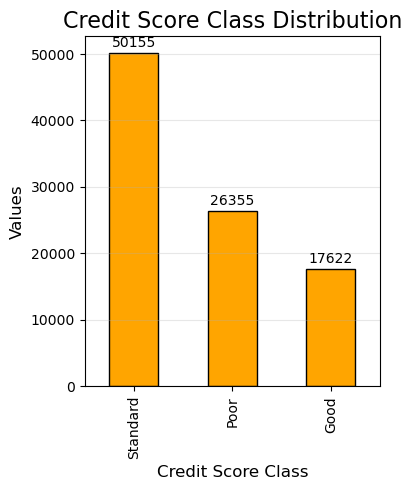

In [429]:
# Visualizing the imbalanced data

plt.figure(figsize=(4,5))
ax = class_counts.plot(kind='bar', color='orange', edgecolor='black', legend=False) # creating a bar plot to visualize the class imbalances

for i, count in enumerate(class_counts):
    plt.text(i, count + max(class_counts)*0.01, str(count), ha='center', va='bottom') # display the value counts on top of the plot

plt.title('Credit Score Class Distribution', fontsize=16) # display the title for the plot
plt.xlabel('Credit Score Class', fontsize=12) # display the x-axis label 
plt.ylabel('Values', fontsize=12) # display the y-axis label 
plt.grid(axis='y', alpha=0.3)
plt.tight_layout() # improves plot layout to prevent overlapping elements
plt.show()

- We can see that the dataset is imbalanced. The 'Standard' class has 50155 values making it the Majority class, while the other two classes, 'Poor' and 'Good' are much lower (Minority class). This means that we need to treat the values such that the samples are balanced.
- We need to use SMOTE to treat the imbalanced data as they would generate new synthetic data using KNN which would add value to the dataset while oversampling the minority class.

### Exploratory Data Analysis

<b>1. Age Distribution (Basic Demographics)</b>

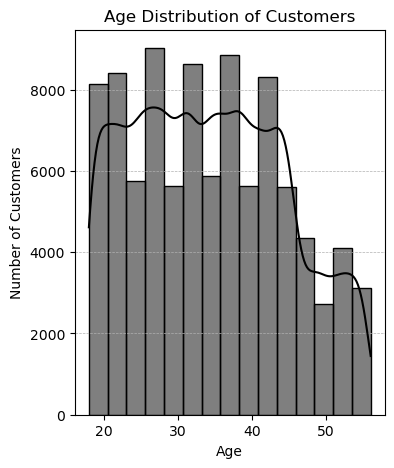

In [430]:
# Creating a histogram to visualize the Age distribution within the data
plt.figure(figsize=(4,5))
sns.histplot(df['Age'],bins=15,kde=True,color='black')
plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.grid(axis='y',linestyle='--',linewidth=0.5)
plt.show()

- This histogram was plotted to understand the age distribution of the customers in the dataset after the unrealistic age values were removed.
- It is important to understand the ages of customers such that appropriate recommendations can be given to them based on their age and experience.
- Knowing the ages of the customers helps us understand key market segments and tailor product offerings like (youth credit-builder loans or retirement solutions) and design age-relevant marketing campaigns.
- Age visuals help anticipate major transitions such as upcoming retirements, young professionals starting their credit journeys or shifts in loan product demands. This allows for more accurate <u>resource planning</u> and <u>timely product launches</u>.
- It could also help us understand the risk profiles different age groups carry (younger users may have low credit history while older users may have lower default risk) and therefore help customize credit scoring.
- In the histogram above, we can see a vast majority of our customers are between the ages of 18 to 45 years. This means that Paisa Bazaar is primarily serving young adults and middle-aged individuals who are in their prime earning, spending and borrowing years. They are often the core customer base as they are the most <u>financially active</u> - they apply for loans, use credit cards, seek investment opportunities and are receptive to digital financial products.

<b>2. Age and Credit Score</b>

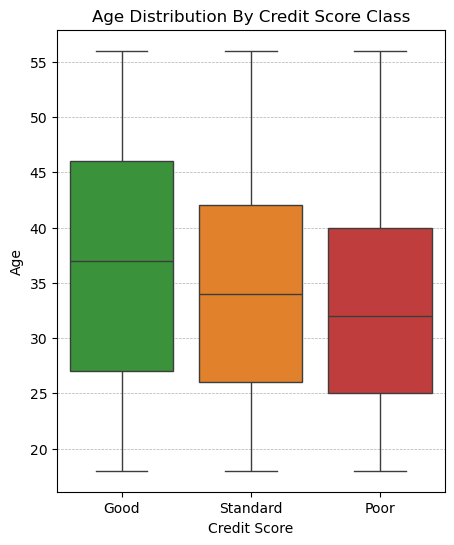

In [431]:
# Creating a boxplot to visualize the relationship between Age and Credit Score
plt.figure(figsize=(5,6))
sns.boxplot(x='Credit_Score',y='Age',data=df, 
           palette={'Good': '#2ca02c', 'Standard': '#ff7f0e', 'Poor': '#d62728'},
            order=['Good', 'Standard', 'Poor'])

plt.title('Age Distribution By Credit Score Class')
plt.xlabel('Credit Score')
plt.ylabel('Age')
plt.grid(axis='y',linestyle='--',linewidth=0.5)
plt.show()

- The one above is a boxplot which was plotted to understand the distribution of credit scores with age, how age affects a customer's score.
- From the plot, we can see that on average, customers who are older, 35 years and above have a 'Good' Credit Score while the customers who are younger, 20-25, have a 'Poor' credit score.
- It does make sense as older customers tend to have more financial literacy as they develop better budgeting habits, debt management skills, long-term planning out of necessity. Older adults often have dependents, mortgages or retirement goals making them more cautious about credit use. They are more likely to <u>prioritize timely payments</u> and <u>maintain lower utilization ratios</u>
- On the other hand, while younger customers have nothing to lose, they would be opening their first credit accounts, might misunderstand repayment terms, miss due dates or max out credit limits which directly impact credit scores in the short term.
- However, this is just a broad understanding of the general patterns observed. There are young people who are financially literate and responsible while more elder customers are not.

<b>3. Average Income and Credit Scores</b>

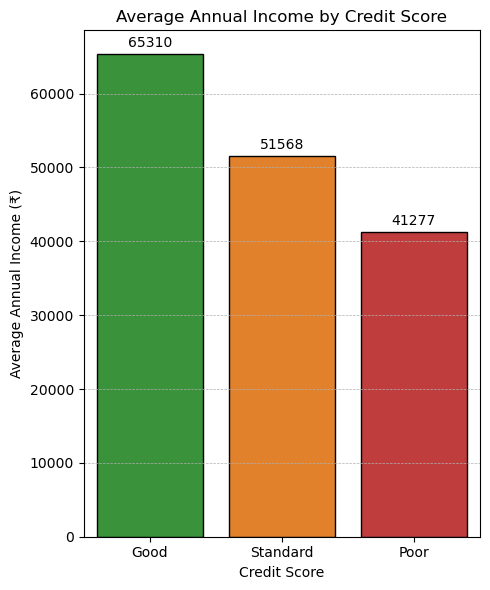

In [24]:
# Creating a bar plot to visualize the relationship between average income and credit scores

plt.figure(figsize=(5, 6))

# Store the barplot in a variable ax
ax = sns.barplot(data=df,x='Credit_Score',y='Annual_Income',estimator=np.mean,ci=None,edgecolor='black',
            palette={'Good': '#2ca02c', 'Standard': '#ff7f0e', 'Poor': '#d62728'},  
            order=['Good', 'Standard', 'Poor'])

# Use ax to generate numerical labels above each bar
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f',padding=3)

plt.title("Average Annual Income by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Annual Income (₹)")
plt.grid(axis='y', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

In [432]:
# Group credit score by average annual income 
avg_df = df.groupby("Credit_Score")["Annual_Income"].mean().sort_values(ascending=False)
avg_df

Credit_Score
Good        65309.586914
Standard    51567.896558
Poor        41277.103845
Name: Annual_Income, dtype: float64

In [433]:
# Calculate the percentage difference in the average income between the ones with 'Good' credit score and the ones with 'Bad' credit score
round((avg_df["Good"]-avg_df["Poor"])/avg_df["Poor"]*100,2)

58.22

- A bar plot was created to visualize the relationship between annual income of customers and their credit scores
- We can see from the figure that there is a clear difference between the categories with the customers having 'Good' credit scores earn 58.22% more than the ones with 'Poor' credit scores.
- This difference makes sense because customers who earn more annually are likely to be able to diversify their credit types, consistently pay off their debts on time, maintain lower credit utilization ratio and avoid missed payments even during emergencies. They are more likely to have <u>lower outstanding debts</u> and therefore better credit scores. 

<b>4. EMI to Monthly Income ratio and Credit Scores</b>

In [434]:
# Create a new feature 'EMI_To_Income_Ratio' to provide more useful insights using solitary features like EMI per month and monthly inhand salary
df['EMI_To_Income_Ratio']=df['Total_EMI_per_month']/df['Monthly_Inhand_Salary']

In [435]:
df.head(5)

,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,EMI_To_Income_Ratio
5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good,0.027167
5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good,0.027167
5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good,0.027167
5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good,0.027167
5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good,0.027167


In [436]:
avg_ratio_by_score = df.groupby('Credit_Score')['EMI_To_Income_Ratio'].mean().sort_values(ascending=True)
avg_ratio_by_score

Credit_Score
Good        0.023399
Standard    0.026875
Poor        0.037109
Name: EMI_To_Income_Ratio, dtype: float64

<b><u>Key</u></b>

1. <u>Low Ratio</u> - EMI is a small portion of income. Plenty of room for savings, emergencies and other expenses
2. <u>Medium Ratio</u> - EMI is manageable but consumes a significant part of income. There is little margin for error
3. <u>High Ratio</u> - EMI exceeds recommended limit and there is high chance of financial stress or default if income drops

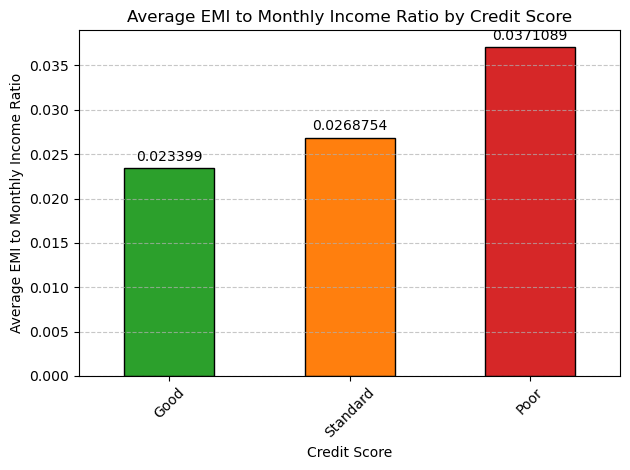

In [32]:
# Creating a bar plot to visualize the relationship between EMI to monthly income ratio and credit score
ax = avg_ratio_by_score.plot(kind='bar', color=['#2ca02c','#ff7f0e','#d62728'], edgecolor='black')

# Generating data labels for each bar
for container in ax.containers:
    ax.bar_label(container,padding=3)
    
plt.title('Average EMI to Monthly Income Ratio by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Average EMI to Monthly Income Ratio')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

- This was a bar plot created to visualize the relationship between the ratio of the Total EMI per month to the monthly in hand salary and the credit score.
- The idea behind this was that sometimes customers have low monthly income and they have to pay high EMI amounts per month which adds to their financial burdens and in times when there is difficulties or their source of income is affected, then it becomes difficult for them to pay the EMIs on time thereby negatively affecting their credit scores.
- This is supported by this graph where customers that have 'Good' credit scores have a low EMI to monthly income ratio (about 0.024) compared to the customers with 'Poor' credit scores (about 0.036).
- The plot shows us that customers with a high EMI burden are likely over-leveraged, they may miss payments further damaging their credit scores.
- These customers can be identified and debt consolidation or financial counseling can be offered to them. This would help in customer conversion and drive loyalty

<b>5. Interest Rate and Credit Scores</b>

In [437]:
df.groupby("Credit_Score")["Interest_Rate"].mean()

Credit_Score
Good         7.571331
Poor        19.860975
Standard    13.529479
Name: Interest_Rate, dtype: float64

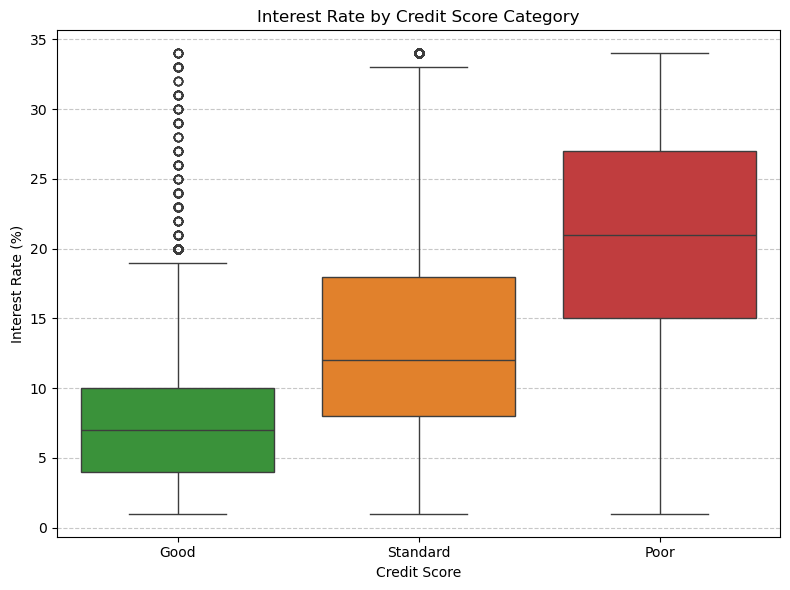

In [438]:
# Creating a box plot to understand the relationship between interest rate and credit scores

plt.figure(figsize=(8, 6))

sns.boxplot(x='Credit_Score',y='Interest_Rate',data=df,
            palette={'Good': '#2ca02c', 'Standard': '#ff7f0e', 'Poor': '#d62728'},
            order=['Good', 'Standard', 'Poor'])
    
plt.title('Interest Rate by Credit Score Category')
plt.xlabel('Credit Score')
plt.ylabel('Interest Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

- This boxplot was created to understand the relationship between interest rates and credit scores.
- We can see that customers that have 'Good' scores have on average lower interest rates than customers with 'Poor' credit scores.
- This can be explained by the fact that having a good credit score makes the customer trustworthy in the eyes of the bank that lends out the loan. They perceive him/her as creditworthy and if they loan them money, they know that they would receive the amount within the duration so they reward such customers with better rates
- Whereas, customers which have poor interest rates are seen as high risk customers and therefore lenders charge more interest rates to compensate for potential losses
- For customers in the poor credit score category, a high interest rate also adds onto the monthly EMI they pay which amounts to the financial burden
- We can use this information for risk-based pricing where high-scoring customers would get lower rates while low scoring customers get higher rates and offering low rates would attract quality borrowers while conversely, higher rates helps avoid bad debt.
- This also in a way incentivizes the customers that if you are able to improve your credit score, you can get your interest rates lowered. 

<b>6. Payment Behavior and Age</b>

<b>Key</b>
1. <b>Low_spent_Small_value_payments</b> - the customers spend little overall, each transaction is small (suggests a cautious spender, low income group)   
2. <b>High_spent_Medium_value_payments</b> - the customers spend a lot overall but most transactions are mid-sized (suggests an active shopper, credit for groceries, electronics, dining)    
3. <b>High_spent_Large_value_payments</b> - the customers have a high total spending with big ticket transactions (suggests high-income, luxury spender maybe)
4. <b>Low_spent_Medium_value_payments</b> - the customers have low total spending but occasional mid-sized transactions (suggests an infrequent user and may use credit for specific needs)
5. <b>High_spent_Small_value_payments</b> - the customers have a high total spending but mostly small transactions (suggests high transaction volume)
6. <b>Low_spent_Large_value_payments</b> - the customers have a low overall spending but one or two big transactions (suggests a rare big spender. For eg: buys a phone once a year on EMI)

In [439]:
df["Payment_Behaviour"].value_counts()

Payment_Behaviour
Low_spent_Small_value_payments      26663
High_spent_Medium_value_payments    18639
High_spent_Large_value_payments     14066
Low_spent_Medium_value_payments     13548
High_spent_Small_value_payments     11060
Low_spent_Large_value_payments      10156
Name: count, dtype: int64

In [440]:
# Creating age categories for the visualization
bins = [18, 30, 50, 80]
labels = ['18-30', '31-50', '51+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True) # categorize Age into discrete groups

In [441]:
# Creating contingency table
ct = pd.crosstab(df['Age_Group'], df['Payment_Behaviour'])

# Normalizing to show percentages within each age grou
ct_pct = pd.crosstab(df['Age_Group'], df['Payment_Behaviour'], normalize='index')*100

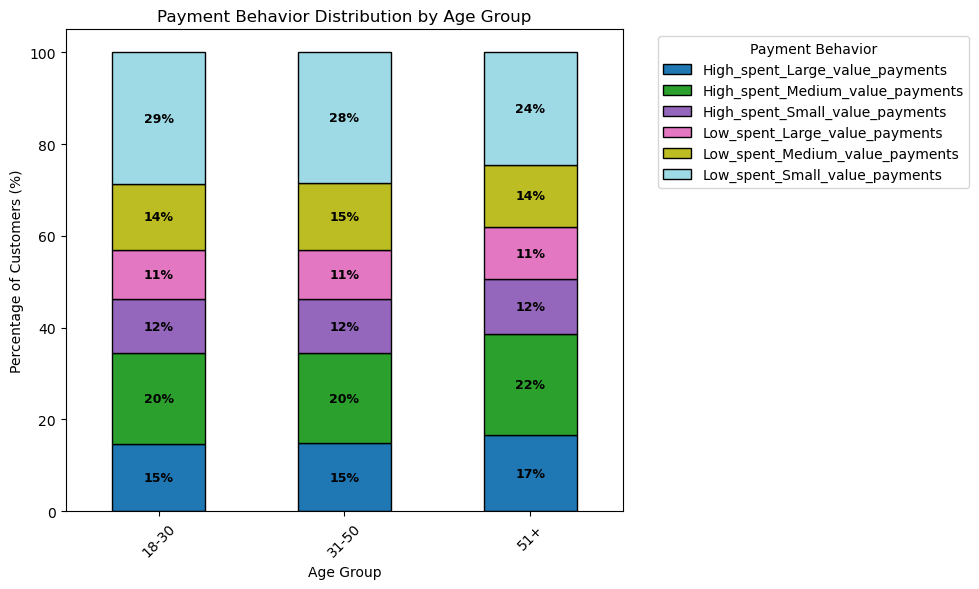

In [442]:
# Creating a stacked bar plot to visualize the relationship between age groups and their payment behaviors
ax = ct_pct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20', edgecolor='black')

plt.title('Payment Behavior Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Percentage of Customers (%)')
plt.xticks(rotation=45)
plt.legend(title='Payment Behavior', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adding labels inside each segment
for c in ax.containers:
    if not c:
        continue
    # Add labels with 0 decimal places and centered
    ax.bar_label(c, fmt='%.0f%%', label_type='center', fontsize=9, color='black', fontweight='bold')

plt.tight_layout()
plt.show()

- This stacked bar chart was created to visualize the difference in age of customers and their payment behavior.
- From this graph, we can see that elder customers tend to have a higher percentage 'High_spent_Large_value_payments' which means they are likely to spend more because they have a higher income and because of family responsibilities et cetera, they need to spend more compared to younger customers who have less responsibilities

<b>7. Credit Mix and Credit Score</b>

In [443]:
# A pivot table to understand the distribution of credit mix and credit score types
ct = pd.crosstab(df['Credit_Mix'],df['Credit_Score'])
print (ct)

Credit_Score   Good   Poor  Standard
Credit_Mix                          
Bad             299  12660      8129
Good          14848   4851     10685
Standard       2475   8844     31341


<Figure size 1000x600 with 0 Axes>

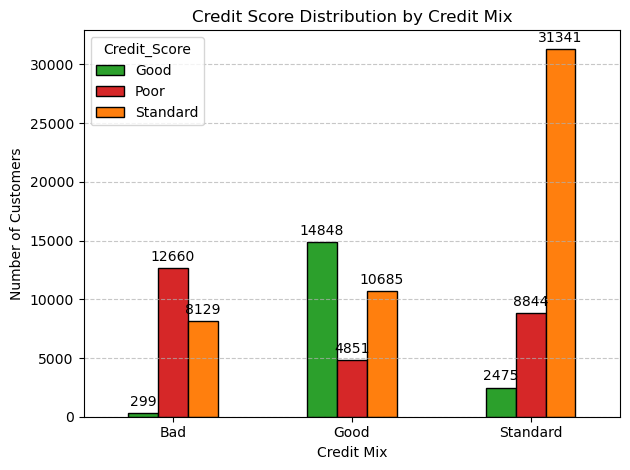

In [444]:
# Creating a grouped bar chart to see if the credit mix of a customer affects their credit scores
plt.figure(figsize=(10,6))
ax = ct.plot(kind='bar',color=['#2ca02c', '#d62728', '#ff7f0e'],edgecolor='black')

# Data labels above each bar
for container in ax.containers: # comes from Matplotlib Axes class
    ax.bar_label(container, fmt='%.0f', padding = 3)
    
plt.title("Credit Score Distribution by Credit Mix")
plt.xlabel("Credit Mix")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Credit_Score")
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

- This <b>grouped bar chart</b> was created to understand the relationship between the different categories of credit mix and how they impact credit scores.
- The idea was that customers with a bad credit mix will have a poor credit score compared to customers with a good credit mix.
- There can be different types of credits in a credit mix such as: revolving credits, installment credits, mortgage credits, open credits et cetera.
- A good credit mix means that the customer has multiple types of credit accounts managed responsibly while a bad credit mix involves having just one type of credit, too many similar accounts or no installment loans for example. It gives a poor impression to the lender that the customer cannot handle loans, is stressed financially and therefore have negative impact on the credit score
- This grouped bar chart supports this argument as we can see there are very few customers with a bad credit mix having a good credit score. A majority of these customers have a 'Poor' credit score. On the contrary, a majority of customers with a good credit mix eventually have a good credit score.
- Understanding the impact of credit mix on credit scores help us segment our customers better and differentiate between low risk and high risk customers to which we can provide different products and services. Low risk customers with a good credit score could be eligible for low interest loans, high-limit credit cards while high risk customers could be given financial education, tips to help them improve their scores.

<b>8. Credit History Age and Credit Score</b>

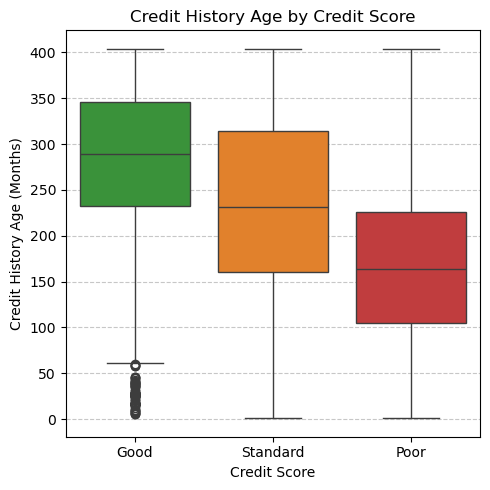

In [445]:
# Visualizing the relationship between a customer's credit history age and credit score
plt.figure(figsize=(5, 5))

# Creating a boxplot
sns.boxplot(
    x='Credit_Score',
    y='Credit_History_Age',
    data=df,
    palette={'Good': '#2ca02c', 'Standard': '#ff7f0e', 'Poor': '#d62728'},
    order=['Good', 'Standard', 'Poor']
)
plt.title('Credit History Age by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Credit History Age (Months)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

- The boxplot was created to visualize the relationship between the age of credit history and the credit score as the credit age determines the length of time an individual has been managing credit, which lenders would use to assess financial responsibility and risk.
- We can see that customers with 'Good' credit scores have longer credit age histories compare to the ones with a 'poor' credit score and it makes sense because it shows lenders that the customers have a proven track record of borrowing and repaying money over time.
- Borrowers with short credit histories are seen as riskier because there is less data to judge their reliability.

<b>9. Multi-collinearity between input features</b>

In [446]:
numeric_df = df.select_dtypes(include=['int64', 'float64']) # selecting columns with numerical datatypes

In [447]:
corr_matrix = numeric_df.corr() # generating the correlation matrix for each column

In [448]:
threshold = 0.70 
# setting a correlation threshold of 0.70. Any column with correlation above this threshold should be removed

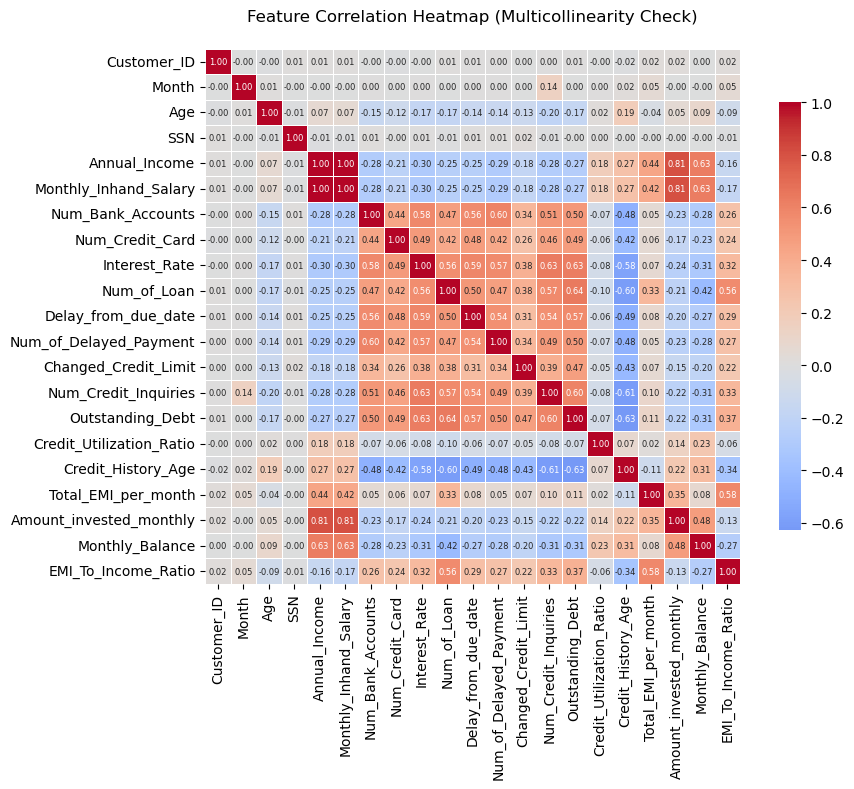

In [449]:
# Generating a heatmap to visualize the correlations between the numerical variables within the data
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm', center=0,square=True,linewidth=0.5,
            cbar_kws={"shrink":0.8}, annot_kws={"size": 6})

plt.title("Feature Correlation Heatmap (Multicollinearity Check)", pad = 20)
plt.tight_layout()
plt.show()

- This heatmap was created to understand whether any of the input features are correlated with each other and if so identify them and remove one of them to ensure that the model learns new features everytime and they don't affect its predictions. Moreover, it is essential that the input features have a relationship with the target variable, 'Credit_Score' and not the other features
- For this visualization, a threshold of +-0.70 was set so that any features beyond are highly correlated and they must be treated
- From this heatmap, we can see that Annual_Income and Monthly_Inhand_Salary have a very strong positive correlation with each other and it is expected as the Monthly_Inhand_Salary is a major part of the Annual_Income. We need to remove either one of these features from our data
- Another observation is that Amount_invested_monthly also has a high correlation of 0.81 with both Annual_Income and Monthly_Inhand_Salary so we need to remove the Amount_invested_monthly column as we have other important factors such as Credit_History_Age or Payment_Behavior

## Data Processing for the Model

<b>Creating a deep copy of the original data</b>

- This is done to ensure that whatever changes we make, it is done to the copy and in case of an error, we have the original dataset as reference. 

In [567]:
df_copy = df.copy(deep=True)
df_copy.head(5)

,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,EMI_To_Income_Ratio,Age_Group
5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good,0.027167,18-30
5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good,0.027167,18-30
5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good,0.027167,18-30
5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good,0.027167,18-30
5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,...,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good,0.027167,18-30


In [568]:
df_copy.shape

(94132, 29)

<b>Removing Irrelevant Features</b>

- From the basic overview of our data, we know that columns like customer_ID, month, Name, SSN do not provide any valuable information in the model building process as they are personal details of the customers. So, it is better to remove them to simplify the model.
- Secondly, from the heatmap, it was observed that columns like Monthly_Inhand_Salary, Amount_invested_monthly are also unnecessary features as they were highly correlated with the Annual_Income column and have better alternatives in Credit_History_Age, Payment_Behavior.
- We also have a column Total_EMI_per_month which is unnecessary as the column EMI_to_Income ratio provides a better metric. We can therefore remove these columns from our dataset.
- There is also a column 'Changed_Credit_Limit' which doesn't provide any predictive value because we have a column 'Credit_Utilization_Ratio' that captures these values including the customer's changed credit limit
- Lastly, there is a column 'Age_Group', which we created for our visualization and it is not needed given that we already have an 'Age' column.
- In total, there are 9 columns that we can remove as they add no value in the model training process.

In [569]:
df_copy.columns

Index(['Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score', 'EMI_To_Income_Ratio', 'Age_Group'],
      dtype='object')

In [570]:
# listing the columns to drop 
columns_to_drop = ["Customer_ID","Month","Name","SSN","Monthly_Inhand_Salary","Amount_invested_monthly",
                   "Total_EMI_per_month","Changed_Credit_Limit","Age_Group"]

In [571]:
# Dropping the irrelevant features
df_copy = df_copy.drop(columns = columns_to_drop, axis=1)

In [572]:
df_copy.shape # Now, there are just 20 features in the dataset

(94132, 20)

#### <b>Feature Engineering</b>

<b>Creating the types of loan feature</b>

- Within our dataset, there is a column called 'Type_of_Loan' which stores different types of loans the customers have separated by ',' and ', and'. However, this data is of no use to us as we won't be able to encode them into different categories and feed it to train our model because there are a lot of variations within it.
- The categories themselves aren't unique and have a lot of repeated values which make it difficult for the model to understand and find any meaningful patterns
- Therefore, it is better to convert this into a numerical column by counting the unique instances of each loan type within the column and storing it which would represent the diversity of loans taken by the customer and provide valuable information for the model to learn.

In [573]:
df_copy['Type_of_Loan']

5634      Auto Loan, Credit-Builder Loan, Personal Loan,...
5635      Auto Loan, Credit-Builder Loan, Personal Loan,...
5636      Auto Loan, Credit-Builder Loan, Personal Loan,...
5637      Auto Loan, Credit-Builder Loan, Personal Loan,...
5638      Auto Loan, Credit-Builder Loan, Personal Loan,...
                                ...                        
155625                          Auto Loan, and Student Loan
155626                          Auto Loan, and Student Loan
155627                          Auto Loan, and Student Loan
155628                          Auto Loan, and Student Loan
155629                          Auto Loan, and Student Loan
Name: Type_of_Loan, Length: 94132, dtype: object

In [574]:
import re
df_copy["loan_list"] = df_copy['Type_of_Loan'].astype(str).apply(lambda x: re.split(r',\s*and\s*|,\s*', x) 
                                                                 if pd.notna(x) and x != 'nan' else [])
# Uses regex to split the types of loan column on both ', ' and ', and'

In [575]:
# Remove empty strings and whitespace
df_copy['loan_list'] = df_copy['loan_list'].apply(
    lambda x: [loan.strip() for loan in x if loan.strip() and loan != 'None'])

In [576]:
# Count the number of unique loan types in each row
df_copy['Loan_Types'] = df_copy['loan_list'].apply(lambda x: len(set(x)))

In [577]:
# Print the values of the new column 'Loan_Types' against the old type_of_loan
print (df_copy[['Type_of_Loan','Loan_Types']].head(5))

                                           Type_of_Loan  Loan_Types
5634  Auto Loan, Credit-Builder Loan, Personal Loan,...           4
5635  Auto Loan, Credit-Builder Loan, Personal Loan,...           4
5636  Auto Loan, Credit-Builder Loan, Personal Loan,...           4
5637  Auto Loan, Credit-Builder Loan, Personal Loan,...           4
5638  Auto Loan, Credit-Builder Loan, Personal Loan,...           4


In [578]:
df_copy.head(3)

,Age,Occupation,Annual_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Payment_Behaviour,Monthly_Balance,Credit_Score,EMI_To_Income_Ratio,loan_list,Loan_Types
5634,23.0,Scientist,19114.12,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,7.0,...,809.98,26.822620,265.0,No,High_spent_Small_value_payments,312.494089,Good,0.027167,"[Auto Loan, Credit-Builder Loan, Personal Loan...",4
5635,23.0,Scientist,19114.12,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,4.0,...,809.98,31.944960,266.0,No,Low_spent_Large_value_payments,284.629162,Good,0.027167,"[Auto Loan, Credit-Builder Loan, Personal Loan...",4
5636,23.0,Scientist,19114.12,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,7.0,...,809.98,28.609352,267.0,No,Low_spent_Medium_value_payments,331.209863,Good,0.027167,"[Auto Loan, Credit-Builder Loan, Personal Loan...",4


- Now that we have the count of the types of loan stored in the list, we can remove the unnecessary columns from our dataset like 'Type_of_Loan' and 'loan_list'.

In [579]:
# Removing the type of loan and loan list columns from the dataset
df_copy = df_copy.drop(columns = ['Type_of_Loan','loan_list'], axis = 1)

In [580]:
df_copy.head(3) # we can see the columns have been removed from our data

,Age,Occupation,Annual_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Payment_Behaviour,Monthly_Balance,Credit_Score,EMI_To_Income_Ratio,Loan_Types
5634,23.0,Scientist,19114.12,3.0,4.0,3.0,4.0,3.0,7.0,4.0,Good,809.98,26.822620,265.0,No,High_spent_Small_value_payments,312.494089,Good,0.027167,4
5635,23.0,Scientist,19114.12,3.0,4.0,3.0,4.0,3.0,4.0,4.0,Good,809.98,31.944960,266.0,No,Low_spent_Large_value_payments,284.629162,Good,0.027167,4
5636,23.0,Scientist,19114.12,3.0,4.0,3.0,4.0,3.0,7.0,4.0,Good,809.98,28.609352,267.0,No,Low_spent_Medium_value_payments,331.209863,Good,0.027167,4


#### <b>Encoding the categorical variables</b>

In [581]:
# Obtaining the categorical variable columns
object_columns = df_copy.select_dtypes(include=['object']).columns.tolist()
print (f"Object columns: {object_columns}")

Object columns: ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Credit_Score']


In [582]:
df_copy["Credit_Mix"].value_counts()

Credit_Mix
Standard    42660
Good        30384
Bad         21088
Name: count, dtype: int64

<b>Label Encoding the Categorical features</b>

- Given that we want to encode these variables and ensure that we don't increase the nummber of dimensions within the dataset with One Hot Encoding, we can apply Label Encoding on them.

In [583]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

columns_to_encode = ['Credit_Mix','Credit_Score', 'Payment_of_Min_Amount','Occupation','Payment_Behaviour']

for col in columns_to_encode:
    df_copy[col] = le.fit_transform(df_copy[col])
    print (f"{col} mapping: {dict(zip(le.classes_,le.transform(le.classes_)))}\n")

Credit_Mix mapping: {'Bad': 0, 'Good': 1, 'Standard': 2}

Credit_Score mapping: {'Good': 0, 'Poor': 1, 'Standard': 2}

Payment_of_Min_Amount mapping: {'NM': 0, 'No': 1, 'Yes': 2}

Occupation mapping: {'Accountant': 0, 'Architect': 1, 'Developer': 2, 'Doctor': 3, 'Engineer': 4, 'Entrepreneur': 5, 'Journalist': 6, 'Lawyer': 7, 'Manager': 8, 'Mechanic': 9, 'Media_Manager': 10, 'Musician': 11, 'Scientist': 12, 'Teacher': 13, 'Writer': 14}

Payment_Behaviour mapping: {'High_spent_Large_value_payments': 0, 'High_spent_Medium_value_payments': 1, 'High_spent_Small_value_payments': 2, 'Low_spent_Large_value_payments': 3, 'Low_spent_Medium_value_payments': 4, 'Low_spent_Small_value_payments': 5}



In [591]:
df_copy['Credit_Score'].value_counts()

# 'Standard is assigned 2, 'Poor' is assigned 1 and 'Good' is assigned 0

Credit_Score
2    50155
1    26355
0    17622
Name: count, dtype: int64

In [592]:
df_copy["Credit_Mix"].value_counts()

# 'Standard' is assigned 2, 'Good' is assigned 1 and 'Bad' is assigned 0

Credit_Mix
2    42660
1    30384
0    21088
Name: count, dtype: int64

In [586]:
df_copy.head(3) # All the columns have been successfully encoded

,Age,Occupation,Annual_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Payment_Behaviour,Monthly_Balance,Credit_Score,EMI_To_Income_Ratio,Loan_Types
5634,23.0,12,19114.12,3.0,4.0,3.0,4.0,3.0,7.0,4.0,1,809.98,26.822620,265.0,1,2,312.494089,0,0.027167,4
5635,23.0,12,19114.12,3.0,4.0,3.0,4.0,3.0,4.0,4.0,1,809.98,31.944960,266.0,1,3,284.629162,0,0.027167,4
5636,23.0,12,19114.12,3.0,4.0,3.0,4.0,3.0,7.0,4.0,1,809.98,28.609352,267.0,1,4,331.209863,0,0.027167,4


<b>Converting some Float columns into Integer</b>

In [590]:
df_copy.dtypes

Age                         float64
Occupation                    int32
Annual_Income               float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Delay_from_due_date         float64
Num_of_Delayed_Payment      float64
Num_Credit_Inquiries        float64
Credit_Mix                    int32
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount         int32
Payment_Behaviour             int32
Monthly_Balance             float64
Credit_Score                  int32
EMI_To_Income_Ratio         float64
Loan_Types                    int64
dtype: object

- There are some columns within this DataFrame that are float values but they should be taking in integers only. These include: ['Age','Num_Bank_Accounts','Num_Credit_Card','Num_of_Loan', 'Delay_from_due_date','Num_of_Delayed_Payment','Num_Credit_Inquiries']
- We should convert these values into integers just to ensure that all the columns are in their appropriate data types and it doesn't affect the model's performance in any way.

In [593]:
columns_to_convert =  ['Age','Num_Bank_Accounts','Num_Credit_Card','Num_of_Loan', 'Delay_from_due_date','Num_of_Delayed_Payment','Num_Credit_Inquiries']

In [598]:
df_copy[columns_to_convert] = df_copy[columns_to_convert].astype(int)
df_copy.dtypes

Age                           int32
Occupation                    int32
Annual_Income               float64
Num_Bank_Accounts             int32
Num_Credit_Card               int32
Interest_Rate               float64
Num_of_Loan                   int32
Delay_from_due_date           int32
Num_of_Delayed_Payment        int32
Num_Credit_Inquiries          int32
Credit_Mix                    int32
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount         int32
Payment_Behaviour             int32
Monthly_Balance             float64
Credit_Score                  int32
EMI_To_Income_Ratio         float64
Loan_Types                    int64
dtype: object

- We can see that all columns are in their appropriate data types
- Now, we can move on to splitting the data into training and testing sets

<b>Splitting the data into Train and Test</b>

In [599]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

In [600]:
# Creating the X and Y
X = df_copy.drop('Credit_Score',axis=1)
y = df_copy['Credit_Score']

# Splitting the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

<b>Scaling the train and test values for the Logistic Regression model</b>

In [601]:
# Scaling the numerical features, not the encoded features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [602]:
print (X_train_scaled.shape)
print (X_test_scaled.shape)

(75305, 19)
(18827, 19)


<b>Applying SMOTE to handle imbalanced data while training the models</b>

In [603]:
# Applying SMOTE only on the training data for logistic regression
smote = SMOTE(random_state=42)
X_train_lr, y_train_lr = smote.fit_resample(X_train_scaled,y_train)

In [604]:
# Applying SMOTE for random forest and decision tree
smote = SMOTE(random_state=42)
X_train,y_train = smote.fit_resample(X_train,y_train)

In [605]:
print (X_train.shape)
print (X_test.shape)
print (y_train.shape)
print (y_test.shape)

(120372, 19)
(18827, 19)
(120372,)
(18827,)


In [606]:
y_train.value_counts() # each category now has an equal number of values

Credit_Score
2    40124
0    40124
1    40124
Name: count, dtype: int64

### Training and Evaluating the Model

#### <b>Logistic Regression</b>

- Logistic Regression model was chosen for this dataset because, with appropriate scaling, encoding and handling of inconsistencies within the data, it can effectively predict multi-class classification problems like this and deal with the 19 features within the dataset.
- We will train a multinomial logistic regression model as it can compress the three classes into a range of probabilities from 0 to 1 using the sigmoid function.

<b>1. Fitting the model on to our training data</b>

In [607]:
# Importing the Logistic Regression model
from sklearn.linear_model import LogisticRegression

# Initializing LogisticRegression()
lr = LogisticRegression(multi_class='multinomial',solver='saga',max_iter=1000,random_state=42)

In [608]:
lr.fit(X_train_lr,y_train_lr) # fitting the model on to the training data

print (lr.intercept_) # printing the intercepts 
print (lr.coef_) # printing the coefficients

[-0.52912751  0.13787454  0.39125297]
[[ 3.81320591e-02 -1.95489812e-02  9.51595085e-02  1.41093193e-02
  -3.87499130e-01 -4.29396262e-01 -4.17246813e-01 -4.87294541e-01
   6.06789640e-02 -1.20869833e-01 -5.75655541e-01 -2.10088305e-01
  -1.81297781e-02  1.49599367e-01 -9.83590020e-02 -1.98406543e-01
  -1.97399960e-01  3.14960303e-01  1.13889233e-01]
 [-3.85648651e-02  1.38190207e-02 -9.67705679e-02 -7.18494112e-02
   3.08735143e-01  4.23592177e-01  2.01470741e-01  3.58547816e-01
  -1.93361499e-01  2.59804281e-01  6.57009577e-02  6.35891707e-02
   1.43649117e-02 -1.12790328e-01  2.44832051e-02  1.93787757e-01
   1.83704555e-01 -2.11088653e-01  2.55806883e-03]
 [ 4.32805949e-04  5.72996048e-03  1.61105939e-03  5.77400919e-02
   7.87639871e-02  5.80408557e-03  2.15776072e-01  1.28746726e-01
   1.32682535e-01 -1.38934448e-01  5.09954584e-01  1.46499135e-01
   3.76486639e-03 -3.68090386e-02  7.38757970e-02  4.61878623e-03
   1.36954052e-02 -1.03871650e-01 -1.16447302e-01]]


In [609]:
print (list(zip(df_copy.columns[0:-1], lr.coef_.ravel()))) # show which variable has what coefficient values

[('Age', 0.038132059126220905), ('Occupation', -0.01954898117027014), ('Annual_Income', 0.09515950849242223), ('Num_Bank_Accounts', 0.01410931932234006), ('Num_Credit_Card', -0.3874991304301121), ('Interest_Rate', -0.4293962622100745), ('Num_of_Loan', -0.417246812854237), ('Delay_from_due_date', -0.4872945413105066), ('Num_of_Delayed_Payment', 0.06067896398974948), ('Num_Credit_Inquiries', -0.12086983260511368), ('Credit_Mix', -0.5756555414151249), ('Outstanding_Debt', -0.21008830537798573), ('Credit_Utilization_Ratio', -0.018129778078404667), ('Credit_History_Age', 0.14959936661857057), ('Payment_of_Min_Amount', -0.09835900204438267), ('Payment_Behaviour', -0.19840654331711494), ('Monthly_Balance', -0.19739995978878708), ('Credit_Score', 0.3149603028046554), ('EMI_To_Income_Ratio', 0.1138892332263367)]


<b>2. Validating the Model</b>

In [610]:
y_pred = lr.predict(X_test_scaled) # making predictions using the trained model
print (y_pred)

[0 0 2 ... 2 2 1]


In [611]:
y_proba_lr = lr.predict_proba(X_test_scaled) # identifying the predictive probabilities of each class
print (y_proba_lr) 

# If class 0 has the highest probability, then it is selected as the final class

[[0.48245481 0.19055707 0.32698812]
 [0.47058536 0.24848223 0.28093241]
 [0.23900407 0.33056565 0.43043028]
 ...
 [0.1306345  0.14061801 0.72874749]
 [0.23287791 0.19768226 0.56943983]
 [0.05438766 0.74087484 0.20473751]]


<b>Evaluating the Logistic Regression Model</b>

In [612]:
# Evaluating the model using a confusion_matrix, accuracy_score and classification report
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

lr_cfm = confusion_matrix(y_test,y_pred) # confusion matrix
print (lr_cfm)

print ("Classification Report: ")
print (classification_report(y_test,y_pred)) # classification report which will give information about precision, recall and f1-score

lr_acc = accuracy_score(y_test,y_pred) # accuracy will be done on the y_test
print("Accuracy of the Logistic Regression model:",lr_acc)

[[2949   96  480]
 [ 878 3415  978]
 [2152 2034 5845]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.49      0.84      0.62      3525
           1       0.62      0.65      0.63      5271
           2       0.80      0.58      0.67     10031

    accuracy                           0.65     18827
   macro avg       0.64      0.69      0.64     18827
weighted avg       0.69      0.65      0.65     18827

Accuracy of the Logistic Regression model: 0.6484835608434695


<b>Observations</b>
1. We can see that the model accuracy score is 0.64 which is decent but not optimum.
2. From the precision scores, for class 0, only 49% of the values classified as class 0 actually belonged to that class, rest were misclassified. Similarly, only 62% of the ones classified as class 1 belonged to that class however 80% was for class 2 which meant that this model is better able to classifiy the positive instances of class 2 than the others. There is a disparity here.
3. F1-score, for this model, varies from 0.62 to 0.67 shows that it performs moderately well in classifying positive instances of each class and there is still a lot for room for improvement. It still misclassifies many positive instances. It is still not reliable in predicting the positive instances for each class while controlling the false positive and false negatives.

- This is significant because the dataset is imbalanced and after handling the data using SMOTE, the model managed to perform as above

#### Decision Tree Model

- A decision tree model is suitable for credit scoring data because it handles both categorical and numerical features naturally and offers clear, interpretable rules for classification results. 
- It captures complex, non-linear relationships between the input features and credit classes.
- Decision trees provide straightforward explanations for each prediction, which is especially valuable for compliance and auditing in financial settings.

In [617]:
# Importing the Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier 

# Initiliazing the model object
dt = DecisionTreeClassifier(random_state=10,criterion='gini') 

In [618]:
# Fitting the model on to the training data
dt.fit(X_train,y_train)

# Making predictions using the trained model
y_pred = dt.predict(X_test)

In [619]:
y_proba_dt = dt.predict_proba(X_test)

<b>Evaluating the Decision Tree Model</b>

In [620]:
# Using the same metrics as logistic regression to evaluate the decision tree model
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

dt_cfm = confusion_matrix(y_test,y_pred) # confusion matrix
dt_cr = classification_report(y_test,y_pred) # classification report
dt_acc = accuracy_score(y_test,y_pred) # accuracy score

print (dt_cfm)
print (dt_cr)
print (dt_acc)

[[2414  162  949]
 [ 161 3749 1361]
 [1203 1596 7232]]
              precision    recall  f1-score   support

           0       0.64      0.68      0.66      3525
           1       0.68      0.71      0.70      5271
           2       0.76      0.72      0.74     10031

    accuracy                           0.71     18827
   macro avg       0.69      0.71      0.70     18827
weighted avg       0.71      0.71      0.71     18827

0.7114781962075742


In [621]:
# Percentage difference in accuracy and roc_auc score between logistic regression and decision tree model
pct_diff_lr_dt = (dt_acc-lr_acc)/lr_acc * 100
print (round(pct_diff_lr_dt,3))

9.714


<b>Observations</b>

1. The decision tree model outperformed the logistic regression model with an accuracy score of 0.711, which is an increase of 9.714%. It is a descent improvement in predictive performance
2. This can be seen in the overall increase in its precion, recall and F1-scores. From 0.62, 0.62 and 0.67, it increased to 0.66, 0.70 and 0.74 respectively which shows that the decision tree model was able to capture the patterns more effectively compared to the logistic regression and create homogenous groups which could classify the positive instances of each class accurately.

#### <b>Random Forest Model</b>

- A random forest is highly suitable for this data because it builds an ensemble of many decision trees on random subsets of features and samples, then aggregates their predictions.
- This approach greatly improves predictive accuracy and robustness compared to a single tree, reducing the risk of overfitting and handling noise and missing data well.
- Random forest models are widely used in credit scoring for their ability to reveal feature importance and deliver strong, generalizable performance on complex, real-world datasets.

In [622]:
# Importing the Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Initializing the RandomForestClassifier()
rfc = RandomForestClassifier(n_estimators = 100, random_state = 10, bootstrap = True, n_jobs = -1)

In [623]:
# Fitting the model on to the training data
rfc.fit(X_train,y_train)
y_pred = rfc.predict(X_test)

In [624]:
y_proba_rfc = rfc.predict_proba(X_test)

<b>Evaluating the Random Forest Model</b>

In [625]:
rfc_cm = confusion_matrix(y_test,y_pred)
rfc_acc = accuracy_score(y_test,y_pred)
rfc_cr = classification_report(y_test,y_pred)

print (rfc_cm)
print (rfc_cr)
print (rfc_acc)

[[2931   27  567]
 [  97 4469  705]
 [1004 1216 7811]]
              precision    recall  f1-score   support

           0       0.73      0.83      0.78      3525
           1       0.78      0.85      0.81      5271
           2       0.86      0.78      0.82     10031

    accuracy                           0.81     18827
   macro avg       0.79      0.82      0.80     18827
weighted avg       0.81      0.81      0.81     18827

0.8079354119084294


In [632]:
# Percentage difference between decision tree accuracy and random forest accuracy
pct_diff_dt = (rfc_acc-dt_acc)/dt_acc * 100
round(pct_diff_dt,3)

13.557

In [633]:
# Percentage difference between logistic regression accuracy and random forest accuracy
pct_diff_lr = (rfc_acc-lr_acc)/lr_acc * 100
round(pct_diff_lr,3)

24.588

<b>Observations</b>
1. The Random Forest model has performed the best out of all three models with an accuracy score of 0.8079 which is much 13.557% higher than the decision tree model and 24.588% higher than the logistic regression model.
2. This staggering increase in accuracy can be explained by the fact that random forests are an ensemble model, they combine the predictions of multiple decision trees so they are robust, not affected by outliers, scaling of the data and it can handle imbalanced data effectively
3. The ability to discriminate between the classes is also reflected in the F1-score which is much higher for each class respectively compared to the other two models. It increased from 0.66, 0.70 and 0.74 to 0.78, 0.81, 0.82 reiterating the fact that this model performs better at accurately classifying the positive instances within each class. Such an increase is promising as we need to be able to identify the critical class categories accurately to provide the appropriate services to our customers.

#### Comparing the performance of the three models

In [636]:
# Creating a new DataFrame to store these values
model_df = pd.DataFrame()
model_df['Model Name'] = ['Logistic Regression','Decision Tree', 'Random Forest']
model_df['Model Accuracy'] = [lr_acc,dt_acc,rfc_acc]

In [637]:
model_df

,Model Name,Model Accuracy
0,Logistic Regression,0.648484
1,Decision Tree,0.711478
2,Random Forest,0.807935


- We can see that the Random Forest was the best performing model with a model accuracy of 0.807 compared to the Decision Tree and the Logistic Regression models which had scores of 0.711 and 0.648 respectively.
- Given that there is a stark difference between the three model and Random Forest clearly outperforms the other two, we will proceed with tuning this model to possibly improve its performance.
- It doesn't make sense to spend time tuning the logistic regression and the decision tree models as they have an accuracy far below the random forest model and are unlikely to improve substantially.

#### Tuning the Random Forest Model

<b>Checking Feature Importances</b>

In [638]:
# Looking at how important was each feature in contributing to the final prediction
print (list(zip(X_train[0:-1],rfc.feature_importances_)))

[('Age', 0.039301855485170685), ('Occupation', 0.030458005985602565), ('Annual_Income', 0.049883514895644854), ('Num_Bank_Accounts', 0.03663004091285299), ('Num_Credit_Card', 0.038823153804058846), ('Interest_Rate', 0.10102462577834405), ('Num_of_Loan', 0.023612656326516452), ('Delay_from_due_date', 0.0711924445592904), ('Num_of_Delayed_Payment', 0.039992793885052336), ('Num_Credit_Inquiries', 0.05455500866746019), ('Credit_Mix', 0.08953374287318722), ('Outstanding_Debt', 0.12576820792459187), ('Credit_Utilization_Ratio', 0.04459401826472465), ('Credit_History_Age', 0.07718555286643997), ('Payment_of_Min_Amount', 0.04099697451876632), ('Payment_Behaviour', 0.022848843050634362), ('Monthly_Balance', 0.048800033059123546), ('EMI_To_Income_Ratio', 0.05054217030864076), ('Loan_Types', 0.014256356833897994)]


In [640]:
# Creating a table to identify the most and the least important features
sample = pd.DataFrame()

sample["Column"] = X_train.columns[0:]
sample["Imp_value"] = (rfc.feature_importances_)*100

sample.sort_values("Imp_value",ascending = False)

,Column,Imp_value
11,Outstanding_Debt,12.576821
5,Interest_Rate,10.102463
10,Credit_Mix,8.953374
13,Credit_History_Age,7.718555
7,Delay_from_due_date,7.119244
9,Num_Credit_Inquiries,5.455501
17,EMI_To_Income_Ratio,5.054217
2,Annual_Income,4.988351
16,Monthly_Balance,4.880003
12,Credit_Utilization_Ratio,4.459402


- We can observe that a lot of the features contribute to the predictive outcome of the model.
- The column 'Loan Types' contributes the least but it is still 1.42% of the overall prediction the model makes, therefore, it is important to keep it for the time being.

<b>Selecting the most important features using SelectKBest</b>

- SelectKBest identifies the top k features in the dataset that have the strongest statistical association with the credit score target variable
- From the heatmap, we can see that besides the features that were dropped from the dataset, most didn't display strong multi-collinearity which means that using Select KBest would help us rank the models based on the strength in their relation with the credit score target variable.
- The goal is to find the top 10 features within the dataset 
- The Select KBest uses a statistical test to understand the relationship between the features. In this case, it is the Chi-Squared Test. It requires all the numerical values to be non-negative and our data doesn't have any negative values so it fits the requirements for the test

In [641]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

In [642]:
# setting k = 10, chi-squared test as the scoring function
test = SelectKBest(score_func = chi2, k=10)
fit1 = test.fit(X,y) # fitting the function on to the training data

In [643]:
# Displaying the selected and the eliminated features from the SelectKBest function
selected_features = X.columns[test.get_support()].tolist()
eliminated_features = X.columns[~test.get_support()].tolist()

print ("selected features: ", selected_features)
print ("eliminated features: ", eliminated_features)

selected features:  ['Annual_Income', 'Num_Bank_Accounts', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_History_Age', 'Monthly_Balance']
eliminated features:  ['Age', 'Occupation', 'Num_Credit_Card', 'Credit_Mix', 'Credit_Utilization_Ratio', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'EMI_To_Income_Ratio', 'Loan_Types']


- We can see that Select KBest has chosen important features like 'Num_Bank_Accounts', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Outstanding_Debt', which are obviously proven to be important in determining credit scores
- But, it has also not selected other important features like 'Num_Credit_Card', 'Credit_Mix', 'Credit_Utilization_Ratio', 'EMI_To_Income_Ratio', which are essential for an individual's credit score.
- Select KBest was able to give a clean, stable subset of high-signal features - like delayed payments and outstanding debt which are both statistically significant and relevant to determining credit_scores
- However, we need a bit of domain knowledge to understand that features such as the number of credit cards, the credit mix, credit utilization ratio, EMI to income ratio are also significant predictors of credit score and therefore have decided to add them to our final X data.

In [644]:
# Adding the 4 important features using domain knowledge to the selected features from Select KBest 
always_keep = ['Credit_Mix', 'Num_Credit_Card','Credit_Utilization_Ratio', 'EMI_To_Income_Ratio']
final_features = list(set(selected_features + always_keep)) 
X_final = df_copy[final_features] # this X_final will be used for model training
X_final.head(3)

,Interest_Rate,Num_Credit_Card,Credit_Utilization_Ratio,Annual_Income,Num_of_Delayed_Payment,Num_of_Loan,Delay_from_due_date,Num_Credit_Inquiries,Outstanding_Debt,Monthly_Balance,Credit_Mix,Num_Bank_Accounts,EMI_To_Income_Ratio,Credit_History_Age
5634,3.0,4,26.822620,19114.12,7,4,3,4,809.98,312.494089,1,3,0.027167,265.0
5635,3.0,4,31.944960,19114.12,4,4,3,4,809.98,284.629162,1,3,0.027167,266.0
5636,3.0,4,28.609352,19114.12,7,4,3,4,809.98,331.209863,1,3,0.027167,267.0


In [645]:
X_final.shape

(94132, 14)

<b>Preparing the data for training after feature selection</b>

In [646]:
X_train, X_test, y_train, y_test = train_test_split(X_final,y,test_size=0.2,stratify=y,random_state=42)

In [647]:
# Specify which columns are categorical (e.g., column 10, 15)
smote = SMOTE(random_state=42)
X_train,y_train = smote.fit_resample(X_train,y_train)

In [648]:
print (X_train.shape)
print (y_train.shape)
print (X_test.shape)
print (y_test.shape)

(120372, 14)
(120372,)
(18827, 14)
(18827,)


<b>Hyperparameter Tuning Using RandomizedSearchCV</b>

- The model will be tuned using RandomizedSearchCV such that a random set of hyperparameters are used to train the random forest model rather than the exhaustive GridSearchCV approach which is computationally expensive.
- This is important for exploring large hyperparameter spaces while having less computational time, especially for this dataset.

In [305]:
# Hyperparameter tuning using RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV

In [306]:
# Creating a grid of parameters to train the model on
param_grid = {'n_estimators': [100, 200], 'max_depth': [10, 20, None],'min_samples_split': [2, 5],
              'min_samples_leaf': [1, 2],'max_features': ['sqrt'],'bootstrap': [True]}

In [594]:
# An rfc_rs model object which will use RandomizedSearchCV to train the model 30 times with different combinations of parameteres within the grid
rfc_rs = RandomizedSearchCV(estimator = rfc, param_distributions = param_grid,n_iter=30,scoring ='f1_weighted',
                           cv=4,n_jobs=-1,verbose=1)

In [595]:
rfc_rs.fit(X_train,y_train) # fitting the RandomizedSearchCV model on to the training data

Fitting 4 folds for each of 24 candidates, totalling 96 fits


RandomizedSearchCV(cv=4,
                   estimator=RandomForestClassifier(n_jobs=-1, random_state=10),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'bootstrap': [True],
                                        'max_depth': [10, 20, None],
                                        'max_features': ['sqrt'],
                                        'min_samples_leaf': [1, 2],
                                        'min_samples_split': [2, 5],
                                        'n_estimators': [100, 200]},
                   scoring='f1_weighted', verbose=1)

In [596]:
print("Best Parameters:", rfc_rs.best_params_)
# selecting the best set of hyperparameters to use to re-train the Random Forest model

Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None, 'bootstrap': True}


<b>Retraining the Random Forest Model using these hyperparameters and the SelectKBest features</b>

In [649]:
# Training the tuned model
tuned_rfc = RandomForestClassifier(n_estimators = 200, class_weight = 'balanced',
                                   min_samples_split = 2, min_samples_leaf = 1, max_features = 'sqrt',max_depth = None,
                                   random_state = 10, bootstrap = True, n_jobs = -1)

In [650]:
# Fitting the model on to the training data
tuned_rfc.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=10)

In [651]:
# Making predictions
y_pred = tuned_rfc.predict(X_test)

In [652]:
y_proba_tuned_rfc = tuned_rfc.predict_proba(X_test)

<b>Evaluating the tuned Random Forest Model</b>

In [653]:
# Using the confusion matrix, accuracy_score and classification report to evaluate the model
tuned_rfc_cm = confusion_matrix(y_test,y_pred)
tuned_rfc_acc = accuracy_score(y_test,y_pred)
tuned_rfc_cr = classification_report(y_test,y_pred)

print (tuned_rfc_cm)
print (tuned_rfc_cr)
print (tuned_rfc_acc)

[[2951   17  557]
 [  68 4512  691]
 [ 959 1182 7890]]
              precision    recall  f1-score   support

           0       0.74      0.84      0.79      3525
           1       0.79      0.86      0.82      5271
           2       0.86      0.79      0.82     10031

    accuracy                           0.82     18827
   macro avg       0.80      0.83      0.81     18827
weighted avg       0.82      0.82      0.82     18827

0.8154777712859191


In [662]:
# Comparing the performance of the Random Forest and the tuned model
model_df = pd.DataFrame()
model_df['Model Name'] = ['Random Forest', 'Tuned Random Forest']
model_df['Model Accuracy'] = [rfc_acc, tuned_rfc_acc]

In [663]:
model_df

,Model Name,Model Accuracy
0,Random Forest,0.807935
1,Tuned Random Forest,0.815478


<b>Observations</b>
1. We can observe that the tuned Random Forest Model with feature selection (SelectKBest) and hyperparameter tuning (RandomizedSearchCV) gave a slightly improved model performance compared to the base random forest model.
2. While the base model had a model accuracy of 0.8099, the tuned model gave an accuracy of 0.815
3. The base model had F1-scores pretty similar to the tuned model however for class 1, the tuned model has a 0.01% increase which is quite important when it comes to credit classifications and handling the imbalance within the data
4. The tuned model gave a better precision of 0.75 for class 2 compared to 0.73 for the base model.
5. The two models have the same F1-scores for each class (0.82, 0.82, 0.79).
6. The precision score for the tuned model showed a 0.01% increase as well for class 0 and class 1 compared to the base model.
7. However, the two models had low scores for class 2, although the difference is not substantial, it still shows some amount of bias in its predictions.

#### Final Model Selection

- Based on the difference in accuracy scores and F1-score between the two models, the Tuned Random Forest Model is selected as the one to be used for deployment.

#### Saving the Random Forest Model in a Pickle file

In [674]:
# Using joblib to save the model in a pickle file
import joblib
model = joblib.dump(tuned_rfc, 'credit_score_model.pkl', compress = 3)

#### Making predictions on the Test data

In [661]:
Y_pred = tuned_rfc.predict(X_test) # using the model to make predictions on the test data
tuned_rfc_test_accuracy = tuned_rfc.score(X_test,y_test) # finding the accuracy score on the test data
print ("Tuned Random Forest Model Test Accuracy:", tuned_rfc_test_accuracy)

Tuned Random Forest Model Test Accuracy: 0.8154777712859191


#### Storing the predicted Credit Score Classes for the Test Data

In [665]:
X_test_new = X_test.copy() # preserving the original
X_test_new['Predicted_Credit_Score'] = y_pred # creating a new column to store the predictions in the test data
X_test_new

,Interest_Rate,Num_Credit_Card,Credit_Utilization_Ratio,Annual_Income,Num_of_Delayed_Payment,Num_of_Loan,Delay_from_due_date,Num_Credit_Inquiries,Outstanding_Debt,Monthly_Balance,Credit_Mix,Num_Bank_Accounts,EMI_To_Income_Ratio,Credit_History_Age,Predicted_Credit_Score
24300,5.0,4,33.741255,72617.550,15,2,22,7,1475.91,449.422420,1,3,0.014910,338.0,2
63755,2.0,7,34.055231,126026.190,3,3,13,4,1475.49,862.895380,1,0,0.023366,357.0,2
33945,12.0,7,36.634607,91836.480,20,1,22,3,164.03,667.537829,1,6,0.008090,222.0,1
78693,24.0,9,33.650758,63382.560,8,7,23,9,2441.01,5.612393,2,10,0.070650,138.0,1
68461,5.0,5,37.878170,35871.340,0,1,10,9,525.01,464.559061,1,4,0.007972,296.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86468,20.0,7,24.743983,47406.220,11,0,15,1,890.19,565.214368,2,4,0.000000,360.0,2
36404,21.0,5,23.990095,62925.640,18,2,22,7,2060.33,219.297263,2,7,0.018466,237.0,1
23364,13.0,6,32.785659,60348.920,19,2,8,1,1134.80,231.781577,2,6,0.016164,191.0,2
31388,14.0,5,24.972148,31802.400,10,3,1,3,1369.66,212.632248,2,3,0.017740,312.0,2


<b>Inverse transforming the Credit Scores and the Credit Mix</b>

In [666]:
# Defining reverse mapping for credit scores
# Credit_Mix mapping: {'Bad': 0, 'Good': 1, 'Standard': 2}
# Credit_Score mapping: {'Good': 0, 'Poor': 1, 'Standard': 2}

credit_score_map_inv = {0:'Good',1:'Poor',2:'Standard'}
credit_mix_map_inv = {0:'Bad', 1:'Good', 2:'Standard'}

In [668]:
X_test.head(2)

,Interest_Rate,Num_Credit_Card,Credit_Utilization_Ratio,Annual_Income,Num_of_Delayed_Payment,Num_of_Loan,Delay_from_due_date,Num_Credit_Inquiries,Outstanding_Debt,Monthly_Balance,Credit_Mix,Num_Bank_Accounts,EMI_To_Income_Ratio,Credit_History_Age
24300,5.0,4,33.741255,72617.55,15,2,22,7,1475.91,449.42242,1,3,0.014910,338.0
63755,2.0,7,34.055231,126026.19,3,3,13,4,1475.49,862.89538,1,0,0.023366,357.0


In [669]:
# Reverse encoding the predicted credit score output by replacing them with their original categories
X_test_new["Predicted_Credit_Score"] = X_test_new["Predicted_Credit_Score"].replace(credit_score_map_inv)
X_test_new["Credit_Mix"] = X_test_new["Credit_Mix"].replace(credit_mix_map_inv)
X_test_new.head(5)

,Interest_Rate,Num_Credit_Card,Credit_Utilization_Ratio,Annual_Income,Num_of_Delayed_Payment,Num_of_Loan,Delay_from_due_date,Num_Credit_Inquiries,Outstanding_Debt,Monthly_Balance,Credit_Mix,Num_Bank_Accounts,EMI_To_Income_Ratio,Credit_History_Age,Predicted_Credit_Score
24300,5.0,4,33.741255,72617.55,15,2,22,7,1475.91,449.422420,Good,3,0.014910,338.0,Standard
63755,2.0,7,34.055231,126026.19,3,3,13,4,1475.49,862.895380,Good,0,0.023366,357.0,Standard
33945,12.0,7,36.634607,91836.48,20,1,22,3,164.03,667.537829,Good,6,0.008090,222.0,Poor
78693,24.0,9,33.650758,63382.56,8,7,23,9,2441.01,5.612393,Standard,10,0.070650,138.0,Poor
68461,5.0,5,37.878170,35871.34,0,1,10,9,525.01,464.559061,Good,4,0.007972,296.0,Good


In [670]:
X_test.columns # checking all the columns within the test data

Index(['Interest_Rate', 'Num_Credit_Card', 'Credit_Utilization_Ratio',
       'Annual_Income', 'Num_of_Delayed_Payment', 'Num_of_Loan',
       'Delay_from_due_date', 'Num_Credit_Inquiries', 'Outstanding_Debt',
       'Monthly_Balance', 'Credit_Mix', 'Num_Bank_Accounts',
       'EMI_To_Income_Ratio', 'Credit_History_Age'],
      dtype='object')

In [671]:
X_test.shape

(18827, 14)

#### Saving the Predicted Values in an Excel File

In [672]:
# Storing the predicted credit score values in an excel file
X_test_new.to_excel("Credit Score Prediction.xlsx",header = True)

#### Deploying the Model Using Gradio

<b>Building the Credit Score Predictor Model</b>

In [678]:
# The libraries needed to run the app
import gradio as gr
import joblib
import pandas as pd
import os

# Feature order exactly as the model was trained on
FEATURE_ORDER = [
    'Interest_Rate', 'Num_Credit_Card', 'Credit_Utilization_Ratio',
    'Annual_Income', 'Num_of_Delayed_Payment', 'Num_of_Loan',
    'Delay_from_due_date', 'Num_Credit_Inquiries', 'Outstanding_Debt',
    'Monthly_Balance', 'Credit_Mix', 'Num_Bank_Accounts',
    'EMI_To_Income_Ratio', 'Credit_History_Age'
]

# Label maps (updated according to the Label Encoding)
label_map = {0: "Good", 1: "Poor", 2: "Standard"}
credit_mix_map = {"Standard": 2, "Good": 1, "Bad": 0}

# Loading the trained Tuned Random Forest Model with error handling
def load_model():
    try:
        if not os.path.exists('credit_score_model.pkl'): # check if the pickle file exists in the directory
            raise FileNotFoundError("credit_score_model.pkl not found in current directory") # raise a FileNotFoundError if not found
        model = joblib.load('credit_score_model.pkl') # loading the trained model and saving it in the model object
        if model is None: # check if the model has been loaded
            raise ValueError("Loaded model is None") # gives a ValueError if no model was loaded
        print("Model loaded successfully") # a message to confirm that the model has loaded successfully
        return model
    except Exception as e:
        print(f"Model loading error: {type(e).__name__}: {e}") # The class of error that occurred
        raise

try:
    tuned_rfc = load_model()
except Exception as e:
    print(f"App cannot start: Model failed to load")
    tuned_rfc = None


def predict_credit_score(
    credit_mix,
    annual_income, num_bank_accounts, num_credit_card, num_of_loan,
    delay_from_due_date, num_of_delayed_payment, outstanding_debt, credit_history_age,
    interest_rate, credit_utilization_ratio, num_credit_inquiries, monthly_balance,
    emi_to_income_ratio
): # defining the parameters to input into the prediction function
    try:
        encoded_credit_mix = credit_mix_map.get(credit_mix, 0) # the encoded credit mix variable to use
        features_list = [
            interest_rate,
            num_credit_card,
            credit_utilization_ratio / 100,
            annual_income,
            num_of_delayed_payment,
            num_of_loan,
            delay_from_due_date,
            num_credit_inquiries,
            outstanding_debt,
            monthly_balance,
            encoded_credit_mix,
            num_bank_accounts,
            emi_to_income_ratio / 100,
            credit_history_age
        ]
        input_data = pd.DataFrame([features_list], columns=FEATURE_ORDER) # inputs features in the same order in which the model was trained on

        prediction = tuned_rfc.predict(input_data)[0] # makes the predictions 
        probabilities = tuned_rfc.predict_proba(input_data)[0] # the probabilities of each prediction to show the confidence in the prediction
        predicted_label = label_map[prediction]

        confidence_text = (
            f"• Poor: {probabilities[1]:.1%}\n"
            f"• Standard: {probabilities[2]:.1%}\n"
            f"• Good: {probabilities[0]:.1%}" # displays the distribution of confidence in each prediction
        )
        return predicted_label, confidence_text

    except Exception as e:
        print(f"Prediction failed: {e}") # prints an error message if the prediction fails and provide a path to resolve the error
        return "Error", "Prediction failed. Check input values or model."

# Custom CSS for bold labels
custom_css = """
<style>
.gradio-container label {
    font-weight: bold !important;
    font-size: 16px !important;
}
.gradio-container .output-label {
    font-weight: bold !important;
}
</style>
""" # bolds all the text within the app, especially the heading and the sub-headings for each feature

with gr.Blocks(
    theme=gr.themes.Base(primary_hue="blue", secondary_hue="blue"), # the basic color theme for the app, the sliders, etc
    head=custom_css
) as demo:
    gr.HTML("""
    <div style="text-align: center; margin: 20px 0;">
        <img src="https://www.paisabazaar.com/PBHP/assets/images/paisabazaar-logo.svg" 
             alt="Paisabazaar Logo" style="height: 120px; width: auto; margin-bottom: 10px;">
        <h1 style="margin: 0; font-size: 32px; color: #1a1a1a;">Paisabazaar Credit Score Predictor</h1>
        <p style="color: #555; font-size: 16px;">Enter your financial details to predict your credit score.</p>
    </div>
    """) # adds the Paisabazaar logo on the top and large enough for the app

    with gr.Row():
        credit_mix = gr.Dropdown(label="Credit Mix", choices=list(credit_mix_map.keys()), value="Standard",
                                info="Select the credit mix type representing your credit account variety")
        annual_income = gr.Number(label="Annual Income (₹)", info="Your total yearly income from all sources")
        num_bank_accounts = gr.Slider(1, 20, value=3, label="Number of Bank Accounts",
                                      info="Total number of accounts you hold across all banks")
    with gr.Row():
        num_credit_card = gr.Slider(0, 10, value=2, label="Number of Credit Cards",
                                    info="Total number of active credit cards you currently own")
        num_of_loan = gr.Slider(0, 10, value=2, label="Number of Active Loans",
                                info="Total number of ongoing loans (e.g., Personal, Home, Auto, Education)")
    with gr.Row():
        delay_from_due_date = gr.Slider(0, 365, value=5, label="Average Delay from Due Date (days)",
                                        info="Average number of days you pay your credit card or loan EMI after the due date")
        num_of_delayed_payment = gr.Slider(0, 50, value=3, label="Number of Delayed Payments",
                                           info="Total number of times you've missed or delayed a payment in the last 24 months")
    with gr.Row():
        outstanding_debt = gr.Number(label="Outstanding Debt (₹)",
                                     info="Total unpaid balance on all of your credit cards and loans")
        credit_history_age = gr.Number(label="Credit History Age (months)", value=360,
                                       info="How long you've had credit accounts, calculated from your oldest account")
    with gr.Row():
        interest_rate = gr.Slider(0, 100, value=12, label="Interest Rate on Loans (%)",
                                  info="Average interest rate on your active loans")
        credit_utilization_ratio = gr.Slider(0, 100, value=30, label="Credit Utilization Ratio (%)",
                                             info="Percentage of your credit limit you are using")
    with gr.Row():
        num_credit_inquiries = gr.Slider(0, 20, value=4, label="Number of Credit Inquiries",
                                         info="Total number of times lenders checked your credit report in the last 12 months")
        monthly_balance = gr.Number(label="Monthly Balance (₹)",
                                    info="Average amount left in your bank at the end of each month")
    with gr.Row():
        emi_to_income_ratio = gr.Slider(0, 100, value=40, label="EMI to Income Ratio (%)",
                                        info="Percentage of income to EMI payments")
        
# creates the rows within the app, the sliders allowing users to interact with the app, change the values 

    predicted_score = gr.Label(label="Your Credit Score") # creates a label for the final prediction
    confidence = gr.Textbox(label="Prediction Confidence Breakdown") # creates a label for the confidence in each prediction

    gr.Button("Predict").click(
        fn=predict_credit_score,
        inputs=[
            credit_mix,
            annual_income, num_bank_accounts, num_credit_card, num_of_loan,
            delay_from_due_date, num_of_delayed_payment, outstanding_debt, credit_history_age,
            interest_rate, credit_utilization_ratio, num_credit_inquiries, monthly_balance,
            emi_to_income_ratio
        ],
        outputs=[predicted_score, confidence]  # This allows the user to click and obtain the prediction and the confidence in those predictions as the output
    )

if __name__ == "__main__": # launching the app
    try:
        demo.launch(share=True) # error handling while launching the app and creating a shareable link
    except Exception as e:
        print(f"Failed to launch app: {e}") # if app fails to launch then raise an error to notify

Model loaded successfully
* Running on local URL:  http://127.0.0.1:7864
* Running on public URL: https://e678a2a7a32a96e6b6.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<b>Creating the requirements.txt file</b>

In [288]:
""" 
Creating the requirements.txt file which would store all the necessary libraries to import 
on Hugging Face spaces and allow it to build the app using the files
"""
%%writefile requirements.txt
gradio==5.8.0
pandas==2.2.2
joblib==1.4.2
scikit-learn==1.4.2
numpy==1.24.3

Overwriting requirements.txt


### Summary

This Paisabazaar Credit Score Prediction project seeked to assess the creditworthiness of customers by predicting their credit scores by training a model on different important input features such as credit mix, credit utilization ratio, number of active loans and engineered features such as EMI to Income ratio. 

The project started with preprocessing the data, identifying missing values, duplicates, imbalances between classes, then conducting univariate, bivariate and multivariate analysis on the data to visualize the distribution of classes like customer age, the relationship between individual target features and the credit score and find multicollinearity between input features. The next stage involved preparing the data for model training, including removing redundant, irrelevant features, performing feature engineering to produce meaningful features from arbitrary ones like EMI to income ratio and loan types, converting certain float values into integer data types, splitting the data into train and test, scaling the X values, applying SMOTE to handle the imbalanced data. 

After this, the data was fed to train three machine learning models namely, Logistic Regression, Decision Tree and Random Forest and compare their performance using accuracy, precision and F1-scores. From this comparison, Random Forest model was the best performing model and it was further tuned by performing additional feature selection by identifying the top 10 features using Select KBest, adding a couple of more important features using domain knowledge and then carrying out RandomizedSearchCV to find a solid set of hyperparameters to re-train the Random Forest model on. The tuned model performed better than the base and therefore was used for deployment.

The tuned model was saved in a pickle file using Joblib, used to the predict the credit score classes for the test data and then save the predictions in an Excel file. Lastly, the model was used to build a web-based Paisabazaar Credit Score Predictor using Gradio and was hosted on Hugging Face Spaces so that it can be shared and accessed through that link.